# 05 Validation against the USGS creepmeters, and the aperture choice

```
Author: Danielle Lindsay
Environment: tulepond_disp (environment.yml). Run time: about 3 min (bootstraps about 2 min, ladder scoring about 1 min).
```

**What this notebook does.**

1. **Rates.** Compares the InSAR creep with the five USGS creepmeters
   (Langbein et al. 2024) over the InSAR window, three ways (Methods M4): the
   creepmeter's own rate (already fault-parallel); the crossing rate, from a
   stack of up to five `fp_ts.csv` crossings (notebook 03) next to the
   instrument; and the step in the fault-parallel velocity across the trace
   (notebook 02 transects, +/-1000 m), which also includes any distributed
   deformation. Each rate carries a moving-block bootstrap 95 % confidence
   interval, because the time series and the profiles are autocorrelated.
2. **Agreement and noise floor.** Summarises the rate differences over the
   stations (bias, RMS, largest difference) and takes the noise floor of the
   InSAR stack from the detrended InSAR minus creepmeter series.
3. **CFW1 across the Tule Pond windows.** Measures the slip that CFW1, at the
   south end of the Tule Pond section, recorded across each Tule Pond onset
   window of notebook 04, from the raw 10-minute record.
4. **Creepmeter catalogue.** Checks every InSAR onset window (Tule Pond
   against CFW1, Oakland against COZ1) against the creepmeter event catalogue
   of Gittins et al. (2026), which is used for timing only. Tabulates the CFW1
   catalogue events near each Tule Pond window with the InSAR step at CFW1,
   and fits an InSAR step at each catalogued CFW1 event that falls in its own
   acquisition interval.
5. **Transient amplitude.** Registers the fraction of the COZ1 creepmeter
   steps that the InSAR recovers, from notebook 04's joint-model amplitudes
   (`creep_events.csv`).
6. **Aperture ladder.** Scores the cross-fault bins on which the choice of the
   30 to 150 m bin is based. The sweep outputs (`sweep_summary_mp5.csv` and one
   `fp_ts.csv` per bin) come from `data_prep/run07_aperture_sweep.py`, which runs
   notebook 03's chain (`creep_profiles.py`) for each bin. They are fingerprinted
   in the registry and re-scored here on a fixed stack.

**Inputs**: `03_creep_timeseries/fp_ts.csv` and the per-track
`creep_ts_LOS_<track>.csv`; the notebook 02 transects
(`fp_velocity_xfault_swath200m_dist1000m.csv`); `04_event_detection/fig1_inputs.npz`
(the referenced fault-parallel velocity grid of the Fig 1A map);
`04_event_detection/creep_events.csv` (the onset windows `onset_lo` to
`onset_hi` of the Tule Pond and Oakland events, and the joint-model COZ1
amplitudes with the creepmeter steps), `event_fraction_by_crossing.csv` and
`section_lengths.csv`; the fault trace; the five creepmeter records; the
digital catalogue of creepmeter slip events of Gittins et al. (2026, v1.0.0,
`common_paths["gittins_catalogue"]`); the precomputed sweep.

**Outputs** (`outputs/05_validation/`): `station_agreement.csv`,
`gittins_comparison.csv`, `cfw1_gittins_near_windows.csv` (every CFW1
catalogue event near a Tule Pond InSAR window, the source of the catalogue
table in the text), `sweep_ladder_scores.csv`, `05_validation_stats.txt`,
registry rows `05_*`.

**Figures** (in the dated figure folder, .png and .pdf):
`figS_validation_cohmap<coh>_<params>_profile1000m_stack5x200m` (the five
stations, supplement, 600 dpi) and `figS_binning_ladder_coh0.9_mp5_stack4x0.4km`
(the aperture ladder, supplement).

**What to check.** The per-station rates with their confidence intervals
(section 4) and the ensemble agreement and noise floor (section 5); the CFW1
slip across each Tule Pond window beside the InSAR step (section 6); the
catalogue match of each InSAR window (section 7); the COZ1 amplitude recovery,
per event and the mean over the two large events (section 10). Section 8
asserts that dropping the listed creepmeter glitch days leaves the catalogued
creep steps unchanged.

## 1. Imports

In [1]:
import os
import warnings

import insar_utils as utils
import creep_profiles as cp                      # fp_ts reader and the rows near a point along the trace
import model_config
from TulePond_filepaths import (common_paths, creepmeters, params, x_width,
                                dist_min, dist_max, coh_timeseries, min_points, coh_velocity,
                                creepmeter_glitches, gittins_window_pad_days,
                                coz1_large_events_yr, coz1_large_tol_days,
                                paths_out, repo_dir)

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pygmt

## 2. Paths and parameters

The parameters of every step below, with units. The aperture-ladder bins are
listed here so that their precomputed sweep files are fingerprinted in the
registry before anything is read.

In [2]:
notebook = "05_validation"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# bootstraps
block_years = 1.0     # moving-block length for the time bootstraps (carries the annual cycle)
block_m = 100.0       # moving-block length (m) for the spatial step bootstrap
nboot = 2000          # bootstrap resamples
seed = 0

# The creepmeter glitch days (an explicit list, no automatic filter) and the widening of the Tule Pond windows for the
# CFW1 catalogue table are set in TulePond_filepaths (creepmeter_glitches, gittins_window_pad_days).
step_check_mm = 0.1   # dropping the glitch days must change no catalogued creep step by this much or more (mm, asserted)

# The InSAR stack at a creepmeter. fp_ts is indexed by latitude; these half-widths are km along the trace
# (utils.lat_to_km_map of each row against the creepmeter's km).
stack_km = 0.2        # half-window of fp_ts rows to stack at a creepmeter (km; matches the 400 m swath)
stack_widen_km = 1.0  # widened half-window (km) if fewer than 2 rows are usable (CPP1 at the frame edge)
stack_max = 5         # at most this many usable rows, nearest first

# the notebook 02 transects
swath_m = 200.0       # swath half-width (m)
max_dist_m = 1000.0   # transect half-length (m)

# the map panel
fp_clim = 5.0              # map colour range +/- this (mm/yr); the detrended panels span +/- 1.5 x this (mm)
prof_ylim = 7.0            # cross-fault profile panels: y range +/- this (mm/yr)

# the figure layout (cm): 18.3 cm wide after crop (full page width)
fig_width_cm = 18.1        # page width before crop; the label overhang brings it to <= 18.3 cm
row_height_cm = 2.1        # one row per creepmeter
gap_row_cm = 0.35          # between rows (the interior rows carry no x annotation)
map_axis_cm = 0.9          # room left of the map for its distance axis and label (fault_map_panel draws it outside the map)
gap_map_cm = 0.9           # between the map and the first data column
gap_col_cm = 0.6           # between the data columns
annot_offset_cm = 0.1      # B-F: the 'Velocity step' annotation's baseline sits this far above the bottom frame (and in from the right)
legend_clearance_cm = 0.02 # G-K: the legend box's padding above and below its text (GMT's default 4p would lift the text above the annotation)
legend_baseline_cm = 0.04  # G-K: GMT puts a legend line's baseline this far above the bottom of its line cell at 6.5p Helvetica
                           # (measured on a 600 dpi render: the descenders end on the cell bottom, about 0.04 cm below the baseline)
# The bottom line of each G-K legend sits on the baseline of the B-F annotation: box bottom = annotation baseline - padding - baseline height.
legend_offset_cm = annot_offset_cm - legend_clearance_cm - legend_baseline_cm
assert legend_offset_cm >= 0, f"the G-K legend box would hang below the panel frame ({legend_offset_cm:.2f} cm)"
cm_blue = "#0072B2"        # Okabe-Ito blue: the creepmeters
insar_grey = "gray55"      # the InSAR
onset_orange = "#E69F00"   # Okabe-Ito orange, long-dashed 0.9 pt: the InSAR onsets, as the InSAR detection lines of Fig 3A (notebook 14)

# The step across an event window (event_step, section 4), used by the creepmeter glitch check (section 8) and by
# the aperture ladder, which scores how much of the COZ1 creepmeter's step each bin recovers (ladder panel D) across
# the onset windows of the two large Oakland events of notebook 04 (selected in section 6).
collar_yr = 0.75      # inter-event collar each side of a window for the local trend (yr)
min_collar_epochs = 5   # an event is scored only with this many epochs in each collar ...
min_fit_epochs = 12     # ... and this many finite epochs in the two collars together

# CFW1 against the Tule Pond InSAR events (the instrument sits at the south end of the section). The creepmeter
# slip across each InSAR onset window is measured from the raw record, allowing for its gaps (section 6). Whether
# CFW1 or COZ1 recorded a creep event is read from the catalogue of Gittins et al. (2026) (section 7).
cfw_edge_hours = 12   # slip across a window = median of the samples in the last 12 h before it closes minus
                      # the median in the first 12 h after it opens (nearest available samples if those are in a gap)
min_edge_samples = 6  # an edge needs this many 10-minute samples (1 h of data)
edge_search_days = 5  # if the edge is in a gap, use the nearest data within this many days
cfw1_insar_half_km = 0.2   # the InSAR step at CFW1 (section 8): mean of 04's per-crossing steps within +/- this (km) along the
                           # trace of CFW1; its noise from the same mean at every COZ1 control event in independent windows of
                           # 2 x this along the Tule Pond section
noise_n_trials = 40        # section 9: the noise of a single-interval step at CFW1 = std of the CFW1 mean step at this many trial epochs,
noise_seed = 20261005      # drawn with this seed from the acquisition intervals at least
noise_clear_days = 60      # this far from every 04 onset window and every CFW1 catalogue event of at least
noise_gittins_min_mm = 0.3 # this slip (start to end), and from both ends of the record

# The ladder: bins scored on a fixed stack (4 rows within 0.4 km, no widening), so that every bin averages the
# same number of rows. The sweep was run at coherence 0.9; the chosen bin is also compared at three coherence
# thresholds (section 13). Bins are (inner, outer) distances from the trace in m.
ladder_coh = 0.9
ladder_stack_km = 0.4
ladder_n_stack = 4
fixed_width = [(0, 100), (50, 150), (100, 200), (150, 250), (200, 300), (300, 400), (400, 500)]
growing = [(100, 200), (100, 300), (100, 400), (100, 500), (100, 700)]
original = [(0, 60), (30, 90), (60, 120), (0, 120), (30, 150), (60, 180), (200, 600), (500, 700)]
inner_edge = [(0, 150), (10, 150), (20, 150), (30, 150), (40, 150), (50, 150), (60, 150), (70, 150), (80, 150)]
selected = (int(dist_min * 1000), int(dist_max * 1000))      # the bin the paper uses
excluded_m = 1e3 * model_config.near_trace_cut_km   # m: the near-trace cut of the slip models (the DISP-S1 phase-linking half-width)

# the bins in the order of the four sets; a bin already in an earlier set is not repeated
ladder_bins = []          # (set name, inner m, outer m)
already_listed = []
for set_name, bins in (("fixed", fixed_width), ("growing", growing), ("original", original), ("inner", inner_edge)):
    for inner, outer in bins:
        if (inner, outer) in already_listed:
            continue
        already_listed.append((inner, outer))
        ladder_bins.append((set_name, inner, outer))

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
xf_file = os.path.join(paths_out["02_velocity_decomposition"], f"fp_velocity_xfault_swath{swath_m:.0f}m_dist{max_dist_m:.0f}m.csv")
fig1_file = os.path.join(paths_out["04_event_detection"], "fig1_inputs.npz")   # 04's referenced FP velocity grid of the Fig 1A map
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
lengths_file = os.path.join(paths_out["04_event_detection"], "section_lengths.csv")   # the measured section extents
event_steps_file = os.path.join(paths_out["04_event_detection"], "event_fraction_by_crossing.csv")   # 04's per-crossing joint-model steps
sweep_summary_file = os.path.join(common_paths["sweep_dir"], "sweep_summary_mp5.csv")

# the precomputed sweep files this notebook reads: one fp_ts.csv per ladder bin, and the chosen bin at each coherence
sweep_fp_files = []
for set_name, inner, outer in ladder_bins:
    sweep_tag = f"ap{inner}-{outer}m_coh{ladder_coh:g}_mp{min_points}"
    assert os.path.isdir(os.path.join(common_paths["sweep_dir"], sweep_tag)), f"precomputed sweep bin missing: {sweep_tag}"
    sweep_fp_files.append(os.path.join(common_paths["sweep_dir"], sweep_tag, "fp_ts.csv"))
sweep_summary = pd.read_csv(sweep_summary_file)
selected_by_coh = sweep_summary[sweep_summary.tag.str.startswith(f"ap{selected[0]}-{selected[1]}m")].sort_values("coh")
for sweep_tag in selected_by_coh.tag:
    sweep_fp_file = os.path.join(common_paths["sweep_dir"], sweep_tag, "fp_ts.csv")
    if sweep_fp_file not in sweep_fp_files:
        sweep_fp_files.append(sweep_fp_file)

creepmeter_files = []
for code, lat, lon, name in creepmeters:
    creepmeter_files.append(utils.creepmeter_file(common_paths["creepmeter_dir"], code))

REG = utils.Registry(notebook, common_paths, repo_dir)
track_files = [os.path.join(paths_out["03_creep_timeseries"], f"creep_ts_LOS_{track}.csv") for track in ("ascending", "descending")]
REG.inputs(fp_ts_file, xf_file, fig1_file, lengths_file, events_file, event_steps_file, *track_files, common_paths["fault_profiles"],
           *creepmeter_files, common_paths["gittins_catalogue"], sweep_summary_file, *sweep_fp_files)

Registry for 05_validation: run dfcb9447, git 37da94a


## 3. Load the creep time series, the transects and the creepmeters

The creepmeter records (Langbein et al. 2024) are daily means over the InSAR
window, with the listed glitch days dropped (`utils.daily_creepmeter` with
`creepmeter_glitches` of TulePond_filepaths, which gives the instrument, the
first and last day and the reason). The glitch days were identified by
inspection; no automatic filter is applied. The published creepmeter values
are fault-parallel slip.

The InSAR stack at a creepmeter is the mean and standard deviation of the
nearest usable `fp_ts` rows,

$$\bar d(t) = \frac{1}{N}\sum_{j=1}^{N} d_j(t), \qquad s(t) = \left[\frac{1}{N}\sum_{j=1}^{N} \big(d_j(t) - \bar d(t)\big)^2\right]^{1/2},$$

where $d_j(t)$ is the fault-parallel creep of row $j$ at epoch $t$ (mm) and
$N$ is the number of rows with a finite value at $t$. The rows are those within 0.2 km along
the trace of the creepmeter (`utils.lat_to_km_map`) with more than 50 % finite
epochs, nearest first, at most $N = 5$, which matches the 400 m transect
swath. Where fewer than 2 rows are usable, the window widens to 1 km; the
printout names the station. Each creepmeter's km is that of the trace vertex
nearest its latitude, checked against the vertex nearest it in distance
(within 0.15 km, asserted).

In [3]:
def stack_insar(fp_table, lat, half_km=stack_km, widen_km=stack_widen_km, n_stack=stack_max, exact=False):
    """Mean and standard deviation of the fp_ts rows nearest a latitude along the trace.

    Rows with more than 50 % finite epochs within half_km along the trace are used, nearest first, at most
    n_stack. If fewer than 2 are usable, the window widens to widen_km. With exact=True (the ladder), n_stack
    usable rows inside half_km are required and the window never widens, so every bin is scored on the same
    number of rows.

    Parameters
    ----------
    fp_table : pandas.DataFrame
        Fault-parallel time series, rows latitude (deg), columns decimal year, values mm.
    lat : float
        Latitude of the creepmeter (deg).
    half_km, widen_km : float
        Half-window and widened half-window along the trace (km).
    n_stack : int
        Largest number of rows stacked.
    exact : bool
        Require n_stack rows inside half_km and never widen.

    Returns
    -------
    tuple or None
        (dates, mean, std, n_rows, half-width used in km), or None if no stack can be formed.
    """
    row_km = to_km(fp_table.index.values)                       # fp_ts is indexed by latitude
    centre_km = float(to_km([lat])[0])
    if exact:
        half_widths_km = [half_km]
    else:
        half_widths_km = [half_km, widen_km]
    for half_width_km in half_widths_km:
        usable = cp.rows_near(fp_table, row_km, centre_km, half_width_km + 1e-6)   # > 50 % finite epochs; 1e-6 km keeps the edge rows
        if len(usable) >= 2:
            break
    if len(usable) == 0:
        return None
    if exact and len(usable) < n_stack:
        return None
    nearest_first = np.argsort(np.abs(to_km(usable.index.values) - centre_km), kind="stable")
    usable = usable.iloc[nearest_first[:n_stack]]
    stack_dates = fp_table.columns.values.astype(float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        stack_mean = np.nanmean(usable.values, axis=0)
        stack_std = np.nanstd(usable.values, axis=0)
    return stack_dates, stack_mean, stack_std, len(usable), half_width_km


to_km = utils.lat_to_km_map(common_paths["fault_profiles"])   # latitude -> km from Point Pinole along the trace
trace = pd.read_csv(common_paths["fault_profiles"])
for code, lat, lon, name in creepmeters:                         # check: the km by latitude matches the km by distance to the trace
    trace_east_m = (trace.ft_lon.values - lon) * 111190.0 * np.cos(np.radians(lat))
    trace_north_m = (trace.ft_lat.values - lat) * 111190.0
    nearest_vertex_km = (len(trace) - 1 - int(np.argmin(np.hypot(trace_east_m, trace_north_m)))) * 0.1
    assert abs(float(to_km([lat])[0]) - nearest_vertex_km) < 0.15, \
        f"{code} at {float(to_km([lat])[0]):.1f} km by latitude but {nearest_vertex_km:.1f} km by distance to the trace"

fp_ts = cp.read_creep_ts(fp_ts_file)
t0 = float(fp_ts.columns.min())
t1 = float(fp_ts.columns.max())
xf = pd.read_csv(xf_file)
print(f"fp_ts: {fp_ts.shape[0]} crossings x {fp_ts.shape[1]} epochs, window {t0:.3f} to {t1:.3f} ({t1 - t0:.2f} yr)")
print(f"transects: {len(xf)} pixels at {xf.code.nunique()} creepmeters")

cm_data = {}
insar_stacks = {}
for code, lat, lon, name in creepmeters:
    cm_data[code] = utils.daily_creepmeter(common_paths["creepmeter_dir"], code, t0, t1, creepmeter_glitches)
    stacked = stack_insar(fp_ts, lat)
    assert stacked is not None, f"{code}: no usable fp_ts rows within {stack_widen_km} km along the trace"
    insar_stacks[code] = stacked
    cm_dates, cm_slip = cm_data[code]
    n_rows = stacked[3]
    half_width_used_km = stacked[4]
    if half_width_used_km == stack_km:
        widened_note = ""
    else:
        widened_note = f" (widened to {half_width_used_km:g} km along the trace)"
    print(f"  {code} ({name}): creepmeter {len(cm_dates)} days, {cm_slip[-1]:.1f} mm total; "
          f"InSAR stack of {n_rows} rows{widened_note}")

fp_ts: 611 crossings x 439 epochs, window 2016.674 to 2026.218 (9.54 yr)
transects: 3621 pixels at 5 creepmeters


  CPP1: 2 listed glitch days dropped of 3420: 2017-05-18 to 2017-05-18 (1 d: two 10-min samples at -283.7 mm (~340 mm below the record) pull the daily mean down 4.8 mm); 2018-02-12 to 2018-02-12 (1 d: one 10-min sample at -283.7 mm (~350 mm below the record) pulls the daily mean down 2.4 mm)
  CPP1 (Pinole Point): creepmeter 3418 days, 48.8 mm total; InSAR stack of 5 rows


  CTM1: 0 listed glitch days dropped of 3225
  CTM1 (Temescal): creepmeter 3225 days, 39.9 mm total; InSAR stack of 5 rows


  COZ1: 0 listed glitch days dropped of 3484
  COZ1 (Oakland Zoo): creepmeter 3484 days, 39.7 mm total; InSAR stack of 5 rows


  CHP1: 0 listed glitch days dropped of 3353
  CHP1 (Palisade Street): creepmeter 3353 days, 37.1 mm total; InSAR stack of 5 rows


  CFW1: 0 listed glitch days dropped of 3437
  CFW1 (Fremont): creepmeter 3437 days, 67.2 mm total; InSAR stack of 5 rows


## 4. Rates with bootstrap confidence intervals

**Rates.** The creepmeter rate $v_{\rm cm}$ and the crossing rate
$v_{\rm cr}$ are least-squares straight lines through the daily creepmeter
record and through the finite epochs of the InSAR stack,

$$y(t) = a + v\,t, \qquad \hat v = \frac{\sum_k (t_k - \bar t)(y_k - \bar y)}{\sum_k (t_k - \bar t)^2},$$

where $y_k$ is the cumulative creep at time $t_k$ (mm, decimal years),
$\bar t$ and $\bar y$ are their means, $a$ is the intercept (mm) and $v$ the
rate (mm/yr).

**Velocity step.** The step across the trace in the notebook 02 transect of
each creepmeter is fitted as one straight line with an offset at the trace,

$$v(x) = c_0 + g\,x + v_{\rm st}\,H(x),$$

where $v(x)$ is the fault-parallel velocity (mm/yr) of a pixel at signed
distance $x$ from the trace (m, within 1000 m and the 200 m swath),
$c_0$ the intercept (mm/yr), $g$ the velocity gradient (mm/yr per m),
$H(x) = 1$ for $x > 0$ and 0 otherwise, and $v_{\rm st}$ the
fault-crossing creep rate (mm/yr).

**Moving-block bootstrap**. The residuals $r_k = y_k - \hat y_k$
of each fit are resampled in $\lceil n/L \rceil$ contiguous blocks of $L$
samples, each starting at a uniformly drawn index, joined and cut to the $n$
samples. The resampled residuals $r^*$ are added to the fitted model,
$y^* = \hat y + r^*$, and the model refitted. This is repeated $B = 2000$
times (seed 0), and the 95 % confidence interval is the 2.5th to 97.5th
percentile of the $B$ refitted rates. $L$ is the number of samples in
one year in time (at least 2), and the number of pixels in 100 m along the
sorted profile (at least 3), because both the time series and the profiles
are autocorrelated. Where a 1-sigma is needed, it is taken from the 95 %
interval as if it were Gaussian, $\sigma = (q_{97.5} - q_{2.5}) / 3.92$.

**Differences.** Per station, $\Delta_{\rm cross} = v_{\rm cr} - v_{\rm cm}$,
$\Delta_{\rm step} = v_{\rm st} - v_{\rm cm}$ and the distributed part
$v_{\rm st} - v_{\rm cr}$ (mm/yr), with 1-sigma
$(\sigma_{\rm InSAR}^2 + \sigma_{\rm cm}^2)^{1/2}$.

**Time series.** The creepmeter record $c(t)$ is interpolated linearly to the
InSAR epochs. The cumulative misfit is $m_k = \bar d(t_k) - c(t_k)$ and its RMSE
is $\left(\frac{1}{n}\sum_k m_k^2\right)^{1/2}$ (mm). For the detrended
comparison, each series has its own least-squares straight line removed,
$\tilde d_k$ and $\tilde c_k$ (mm). The detrended correlation is the Pearson
$r$ of $\tilde d$ and $\tilde c$, and the detrended RMSE,

$$E_{\rm det} = \left[\frac{1}{n}\sum_{k=1}^{n} (\tilde d_k - \tilde c_k)^2\right]^{1/2},$$

is the noise floor of the stack (mm), where $n$ is the number of epochs at
which both are finite.

**Step across an event window.** `event_step` measures the slip across one
window $[t_s, t_e]$ against the local inter-event trend. The window edges are
the acquisitions either side of the step (`onset_lo` and `onset_hi` of
notebook 04), so the edge epochs belong to the collars. In the collars,
$t_s - \tau \le t \le t_s$ (pre) and $t_e \le t \le t_e + \tau$ (post),
the model

$$y(t) = a + b\,(t - \bar t) + \Delta\,P(t)$$

is fitted by least squares, where $y$ is cumulative slip (mm), $b$ the common
inter-event rate (mm/yr), $\bar t$ the mean time of the collar epochs, $P(t) = 1$
in the post collar and 0 in the pre collar, $\tau = 0.75$ yr, and $\Delta$ the
step (mm). An event is not scored when a collar has fewer than 5 epochs or the
two collars together fewer than 12 finite epochs. The step gives the ladder's
recovered fraction (section 13) and the creepmeter glitch check (section 8).

In [4]:
rng = np.random.default_rng(seed)


def slope(dates, values):
    """Least-squares slope of values against dates, in closed form so the bootstrap refit is fast.

    Parameters
    ----------
    dates, values : numpy.ndarray
        Times (decimal years) and values (mm).

    Returns
    -------
    float
        Slope (mm/yr).
    """
    dates_centred = dates - dates.mean()
    return float(dates_centred @ (values - values.mean()) / (dates_centred @ dates_centred))


def block_indices(n_samples, block_len):
    """Draw one moving-block resample of sample indices.

    Parameters
    ----------
    n_samples : int
        Length of the series.
    block_len : int
        Number of contiguous samples per block.

    Returns
    -------
    numpy.ndarray
        Indices of ceil(n_samples / block_len) random contiguous blocks, joined and cut to n_samples.
    """
    n_blocks = int(np.ceil(n_samples / block_len))
    starts = rng.integers(0, n_samples - block_len + 1, size=n_blocks)
    blocks = []
    for start in starts:
        blocks.append(np.arange(start, start + block_len))
    return np.concatenate(blocks)[:n_samples]


def block_bootstrap_slope(dates, values, block_len):
    """Rate of a straight line with a moving-block bootstrap 95 % confidence interval.

    The residuals about the line are resampled in blocks of block_len samples, added back to the line and
    refitted nboot times.

    Parameters
    ----------
    dates, values : array_like
        Times (decimal years) and cumulative creep (mm).
    block_len : int
        Block length in samples (bounded to 2 to len(dates)).

    Returns
    -------
    tuple of float
        (rate, ci_lo, ci_hi), mm/yr.
    """
    dates = np.asarray(dates, float)
    values = np.asarray(values, float)
    n_samples = len(dates)
    line = np.polyfit(dates, values, 1)
    trend = np.polyval(line, dates)
    residual = values - trend
    block_len = int(max(2, min(block_len, n_samples)))
    draws = np.empty(nboot)
    for draw in range(nboot):
        draws[draw] = slope(dates, trend + residual[block_indices(n_samples, block_len)])
    return line[0], np.percentile(draws, 2.5), np.percentile(draws, 97.5)


def block_bootstrap_step(dist_m, velocity):
    """Velocity step at the trace with a moving-block bootstrap 95 % confidence interval.

    The residuals are resampled in blocks of about block_m along the distance-sorted profile.

    Parameters
    ----------
    dist_m : numpy.ndarray
        Signed distance from the trace (m).
    velocity : numpy.ndarray
        Fault-parallel velocity (mm/yr).

    Returns
    -------
    tuple of float
        (step, ci_lo, ci_hi), mm/yr.
    """
    order = np.argsort(dist_m)
    dist_m = dist_m[order]
    velocity = velocity[order]
    intercept, gradient, step_best = utils.step_fit(dist_m, velocity)
    prediction = intercept + gradient * dist_m + step_best * (dist_m > 0)
    residual = velocity - prediction
    n_samples = len(dist_m)
    block_len = int(max(3, round(n_samples * block_m / (dist_m.max() - dist_m.min()))))
    draws = np.empty(nboot)
    for draw in range(nboot):
        _, _, draws[draw] = utils.step_fit(dist_m, prediction + residual[block_indices(n_samples, block_len)])
    return step_best, np.percentile(draws, 2.5), np.percentile(draws, 97.5)


def event_step(dates, cumulative, window_start, window_end):
    """Slip across one event window against the local inter-event trend.

    In the collars (collar_yr each side, never inside the window), one straight line with a common slope
    and an offset that applies after the window are fitted together; the offset is the step. The window
    edges are the acquisitions either side of the step (04's onset_lo and onset_hi), so the edge epochs
    belong to the collars.

    Parameters
    ----------
    dates : numpy.ndarray
        Times (decimal years).
    cumulative : numpy.ndarray
        Cumulative slip (mm).
    window_start, window_end : float
        Last pre-event and first post-event sample (decimal years).

    Returns
    -------
    float
        The step (mm), or NaN (not scored) when a collar has fewer than min_collar_epochs epochs or the two
        collars together fewer than min_fit_epochs finite epochs.
    """
    pre = (dates >= window_start - collar_yr) & (dates <= window_start)
    post = (dates >= window_end) & (dates <= window_end + collar_yr)
    if pre.sum() < min_collar_epochs or post.sum() < min_collar_epochs:
        return np.nan
    fit = np.isfinite(cumulative) & (pre | post)
    if fit.sum() < min_fit_epochs:
        return np.nan
    design_matrix = np.column_stack([np.ones(fit.sum()), dates[fit] - dates[fit].mean(), post[fit].astype(float)])
    return float(np.linalg.lstsq(design_matrix, cumulative[fit], rcond=None)[0][2])


rows = []
misfits = {}                              # code -> (InSAR epochs, InSAR minus creepmeter on them, mm); COZ1's is used in section 10
for code, lat, lon, name in creepmeters:
    cm_dates, cm_slip = cm_data[code]
    cm_step_yr = np.median(np.diff(cm_dates))
    cm_rate, cm_lo, cm_hi = block_bootstrap_slope(cm_dates, cm_slip, round(block_years / cm_step_yr))
    stack_dates, stack_mean, stack_std, n_rows, _ = insar_stacks[code]
    finite = np.isfinite(stack_mean)
    insar_dates = stack_dates[finite]
    insar_slip = stack_mean[finite]
    cr_rate, cr_lo, cr_hi = block_bootstrap_slope(insar_dates, insar_slip, round(block_years / np.median(np.diff(insar_dates))))
    transect = xf[(xf["code"] == code) & (xf["dist_m"].abs() <= max_dist_m)]
    st_rate, st_lo, st_hi = block_bootstrap_step(transect["dist_m"].values.astype(float), transect["fp_vel"].values.astype(float))
    cm_on_insar_dates = np.interp(insar_dates, cm_dates, cm_slip)            # creepmeter on the SAR epochs
    misfit = insar_slip - cm_on_insar_dates
    misfits[code] = (insar_dates, misfit)
    insar_detrended = utils.detrend(insar_dates, insar_slip)
    cm_detrended = utils.detrend(insar_dates, cm_on_insar_dates)
    both_finite = np.isfinite(insar_detrended) & np.isfinite(cm_detrended)
    det_r = float(np.corrcoef(insar_detrended[both_finite], cm_detrended[both_finite])[0, 1])
    det_rmse = float(np.sqrt(np.mean((insar_detrended[both_finite] - cm_detrended[both_finite]) ** 2)))
    rows.append(dict(code=code, name=name, nstack=n_rows, nepoch=int(finite.sum()),
                     cm_rate=cm_rate, cm_lo=cm_lo, cm_hi=cm_hi, cr_rate=cr_rate, cr_lo=cr_lo, cr_hi=cr_hi,
                     st_rate=st_rate, st_lo=st_lo, st_hi=st_hi,
                     d_cross=cr_rate - cm_rate, d_step=st_rate - cm_rate, distributed=st_rate - cr_rate,
                     sig_cross=np.hypot(utils.sigma_from_ci95(cr_lo, cr_hi), utils.sigma_from_ci95(cm_lo, cm_hi)),
                     sig_step=np.hypot(utils.sigma_from_ci95(st_lo, st_hi), utils.sigma_from_ci95(cm_lo, cm_hi)),
                     cum_rmse=np.sqrt(np.mean(misfit ** 2)),
                     det_std_ins=np.nanstd(insar_detrended), det_std_cm=np.nanstd(cm_detrended),
                     det_rmse=det_rmse, det_r=det_r))
    print(f"  {code}: creepmeter {cm_rate:5.2f} [{cm_lo:.2f}, {cm_hi:.2f}]  crossing {cr_rate:5.2f} [{cr_lo:.2f}, {cr_hi:.2f}]  "
          f"step {st_rate:5.2f} [{st_lo:.2f}, {st_hi:.2f}]  det r {det_r:.2f}  det RMSE {det_rmse:.2f} mm")
stations = pd.DataFrame(rows).set_index("code")
stations.to_csv(os.path.join(out_dir, "station_agreement.csv"))

  CPP1: creepmeter  5.05 [4.95, 5.14]  crossing  4.91 [4.66, 5.19]  step  3.65 [2.46, 4.78]  det r 0.32  det RMSE 1.66 mm


  CTM1: creepmeter  4.11 [4.02, 4.21]  crossing  4.19 [3.91, 4.48]  step  3.77 [3.32, 4.22]  det r 0.37  det RMSE 1.88 mm


  COZ1: creepmeter  4.43 [4.10, 4.75]  crossing  3.06 [2.83, 3.28]  step  3.09 [2.60, 3.61]  det r 0.58  det RMSE 1.67 mm


  CHP1: creepmeter  3.81 [3.75, 3.86]  crossing  4.20 [4.08, 4.32]  step  4.95 [4.31, 5.58]  det r -0.23  det RMSE 1.64 mm


  CFW1: creepmeter  6.99 [6.77, 7.22]  crossing  6.56 [6.44, 6.68]  step  6.58 [6.14, 7.02]  det r 0.31  det RMSE 1.51 mm


## 5. Ensemble agreement and the noise floor

For one InSAR measure (crossing or velocity step), the differences
$\Delta_i$ from section 4 at the $N$ stations give

$$\text{bias} = \frac{1}{N}\sum_{i=1}^{N}\Delta_i, \qquad \text{RMS} = \left[\frac{1}{N}\sum_{i=1}^{N}\Delta_i^2\right]^{1/2}, \qquad \max_i |\Delta_i|,$$

all in mm/yr. They are computed for the crossing rate at all five stations and
without COZ1, and for the velocity step at all five stations. The noise floor
registered (`05_noise_floor_det_rmse_mm`) is the mean of the detrended RMSE
$E_{\rm det}$ over the five stations. A second definition is registered beside
it: the median standard deviation of the detrended InSAR stack at the stations
whose detrended creepmeter record has a standard deviation below 1 mm.

In [5]:
def agreement(table, key):
    """Agreement of one InSAR measure with the creepmeters over the stations in a table.

    From the differences delta = InSAR - creepmeter (column d_<key>): bias = mean(delta),
    RMS = sqrt(mean(delta^2)) and the largest |delta|.

    Parameters
    ----------
    table : pandas.DataFrame
        The station table of section 4.
    key : str
        'cross' or 'step'.

    Returns
    -------
    dict
        bias, rms and maxabs (mm/yr).
    """
    delta = table[f"d_{key}"].values
    bias = np.mean(delta)
    return dict(bias=bias, rms=np.sqrt(np.mean(delta ** 2)), maxabs=np.max(np.abs(delta)))


agreement_stats = {"cross": agreement(stations, "cross"), "step": agreement(stations, "step"),
                   "cross_excl_coz1": agreement(stations.drop("COZ1"), "cross")}
steady = stations[stations.det_std_cm < 1.0]                # stations whose detrended creepmeter std is below 1 mm
floor_steady_std = float(steady.det_std_ins.median())       # median detrended InSAR std at those stations
floor_rmse = float(stations.det_rmse.mean())

stats_lines = ["=" * 78, "CREEPMETER vs INSAR: CREEP-RATE AGREEMENT", "=" * 78,
               f"InSAR window {t0:.3f} to {t1:.3f} ({t1 - t0:.2f} yr); creep bin {dist_min * 1000:.0f}-{dist_max * 1000:.0f} m, "
               f"along-strike +/-{x_width * 1000:.0f} m, coherence {coh_timeseries}",
               f"velocity-field step: +/-{max_dist_m:.0f} m transects, swath +/-{swath_m:.0f} m; InSAR stack <= {stack_max} rows "
               f"within +/-{stack_km * 1000:.0f} m along the trace",
               f"bootstrap: {nboot} moving-block resamples (block ~{block_years:g} yr / {block_m:.0f} m), seed {seed}", "",
               "PER-STATION RATES (mm/yr) [95% CI]",
               f"{'code':5} {'creepmeter':>22} {'crossing':>22} {'step':>22}"]
for code, station in stations.iterrows():
    stats_lines.append(f"{code:5} {station.cm_rate:6.2f} [{station.cm_lo:5.2f},{station.cm_hi:5.2f}]   "
                       f"{station.cr_rate:6.2f} [{station.cr_lo:5.2f},{station.cr_hi:5.2f}]   "
                       f"{station.st_rate:6.2f} [{station.st_lo:5.2f},{station.st_hi:5.2f}]")
stats_lines += ["", "DIFFERENCES vs CREEPMETER (mm/yr)", f"{'code':5} {'crossing-cm':>12} {'step-cm':>10} {'step-crossing':>14}"]
for code, station in stations.iterrows():
    stats_lines.append(f"{code:5} {station.d_cross:12.2f} {station.d_step:10.2f} {station.distributed:14.2f}")
stats_lines += ["", "TIME-SERIES AGREEMENT (creepmeter aligned to the InSAR epochs)",
                f"{'code':5} {'cum RMSE':>9} {'det.std ins/cm':>16} {'det.r':>7} {'det RMSE':>9} {'N_ep':>5}"]
for code, station in stations.iterrows():
    stats_lines.append(f"{code:5} {station.cum_rmse:9.2f} {station.det_std_ins:7.2f}/{station.det_std_cm:<7.2f} {station.det_r:7.2f} "
                       f"{station.det_rmse:9.2f} {station.nepoch:5d}")
stats_lines += ["", "ENSEMBLE AGREEMENT"]
for key, label in (("cross", "crossing vs creepmeter, all 5"), ("cross_excl_coz1", "crossing vs creepmeter, excl COZ1"),
                   ("step", "velocity step vs creepmeter, all 5")):
    stats = agreement_stats[key]
    stats_lines.append(f"{label}: bias {stats['bias']:+.2f}, RMS {stats['rms']:.2f}, max |diff| {stats['maxabs']:.2f} mm/yr")
stats_lines += ["", "NOISE FLOOR",
                f"median detrended InSAR std at steady stations (creepmeter transient < 1 mm): {floor_steady_std:.2f} mm",
                f"mean detrended RMSE, InSAR minus creepmeter, all 5: {floor_rmse:.2f} mm "
                f"(range {stations.det_rmse.min():.2f} to {stations.det_rmse.max():.2f})"]
print("\n".join(stats_lines))

CREEPMETER vs INSAR: CREEP-RATE AGREEMENT
InSAR window 2016.674 to 2026.218 (9.54 yr); creep bin 30-150 m, along-strike +/-200 m, coherence 0.7
velocity-field step: +/-1000 m transects, swath +/-200 m; InSAR stack <= 5 rows within +/-200 m along the trace
bootstrap: 2000 moving-block resamples (block ~1 yr / 100 m), seed 0

PER-STATION RATES (mm/yr) [95% CI]
code              creepmeter               crossing                   step
CPP1    5.05 [ 4.95, 5.14]     4.91 [ 4.66, 5.19]     3.65 [ 2.46, 4.78]
CTM1    4.11 [ 4.02, 4.21]     4.19 [ 3.91, 4.48]     3.77 [ 3.32, 4.22]
COZ1    4.43 [ 4.10, 4.75]     3.06 [ 2.83, 3.28]     3.09 [ 2.60, 3.61]
CHP1    3.81 [ 3.75, 3.86]     4.20 [ 4.08, 4.32]     4.95 [ 4.31, 5.58]
CFW1    6.99 [ 6.77, 7.22]     6.56 [ 6.44, 6.68]     6.58 [ 6.14, 7.02]

DIFFERENCES vs CREEPMETER (mm/yr)
code   crossing-cm    step-cm  step-crossing
CPP1         -0.14      -1.40          -1.26
CTM1          0.07      -0.35          -0.42
COZ1         -1.37      -1.34

## 6. CFW1: the slip across each Tule Pond InSAR onset window

CFW1 sits at the south end of the Tule Pond section. For each of the five
InSAR onset windows $[t_s, t_e]$ of notebook 04 (from the last acquisition
before the event to the first one after it), the slip the creepmeter recorded
across the window is measured from the raw 10-minute record,

$$S_{\rm win} = \operatorname{med}\{c(t) : t_e - h < t \le t_e\} - \operatorname{med}\{c(t) : t_s \le t < t_s + h\},$$

where $c(t)$ is the CFW1 slip (mm) at sample time $t$ and $h = 12$ h. An edge
needs at least 6 samples (1 h of data). If an edge falls in a data gap, the
nearest 12 h of data on that side within 5 d are used instead. The span
actually measured, $\tilde t_e - \tilde t_s$, is the difference of the
median times of the two sets of samples (printed in days). The expected slip
is $E = v_{\rm CFW1}(\tilde t_e - \tilde t_s)$, where $v_{\rm CFW1}$ is
the CFW1 rate over the InSAR window from section 4 (mm/yr). The data column
is the percentage of whole hours inside the window with at least one sample.

The Oakland (COZ1) control events are read here too: all of them, labelled
by `onset_day`, and the two large ones, the two with the largest creepmeter
steps (`creepmeter_step_mm`). These are asserted to be the January 2019 and
February 2022 events (`coz1_large_events_yr`, each inside its onset window
+/- `coz1_large_tol_days`). The two large events give the mean amplitude
recovery (section 10) and the ladder's step score (section 13); the noise of
the CFW1 step (section 9) uses every COZ1 event.

In [6]:
events_all = pd.read_csv(events_file)
events_coz1 = events_all.query("segment == 'COZ1'")
events_tulepond = events_all.query("segment == 'TULEPOND'")
assert len(events_tulepond) == 5, f"expected the five Tule Pond events, got {len(events_tulepond)}"
assert len(events_coz1) >= 2, f"expected at least the two large Oakland (COZ1) events of notebook 04, got {len(events_coz1)}"
assert events_coz1.onset_day.is_unique, "two COZ1 events share an onset day: their labels would collide"
assert (events_coz1.creepmeter_step_mm > 0).all(), \
    f"a COZ1 control event has no forward creepmeter step: {events_coz1[['onset_day', 'creepmeter_step_mm']].values.tolist()}"
# the two large COZ1 events: the two largest creepmeter steps, which must be the two known events
events_coz1_large = events_coz1.nlargest(2, "creepmeter_step_mm").sort_values("onset_lo")
events_coz1_other = events_coz1.drop(events_coz1_large.index)
if len(events_coz1_other) > 0:
    assert events_coz1_large.creepmeter_step_mm.min() > events_coz1_other.creepmeter_step_mm.max(), \
        "the second and third largest COZ1 creepmeter steps tie: the two large events are not defined"
coz1_tol_yr = coz1_large_tol_days / 365.25
for known_yr, event in zip(sorted(coz1_large_events_yr), events_coz1_large.itertuples()):
    assert event.onset_lo - coz1_tol_yr <= known_yr <= event.onset_hi + coz1_tol_yr, (
        f"the COZ1 event with a large creepmeter step at {event.onset_day} ({event.creepmeter_step_mm:.2f} mm) is not the known "
        f"large event at {known_yr} (TulePond_filepaths coz1_large_events_yr)")
print(f"COZ1 control events: " + ", ".join(f"{event.onset_day} (creepmeter {event.creepmeter_step_mm:.2f} mm)" for event in events_coz1.itertuples())
      + f"; the two large: {events_coz1_large.onset_day.tolist()}")

cfw_raw = utils.read_creepmeter_10min_raw(utils.creepmeter_file(common_paths["creepmeter_dir"], "CFW1"), date_start=t0, date_end=t1)
cfw_dates = cfw_raw.decimal_year.values
cfw_slip = cfw_raw.slip_mm.values
one_day_yr = 1 / 365.25
cfw_rate = stations.loc["CFW1", "cm_rate"]           # the instrument's own rate over the InSAR window, mm/yr


def cfw_level(t_edge, side):
    """Median CFW1 slip in the cfw_edge_hours after or before a window edge.

    If that span has fewer than min_edge_samples samples (the edge is in a gap), the nearest cfw_edge_hours
    of data on that side within edge_search_days are used instead.

    Parameters
    ----------
    t_edge : float
        The window edge (decimal years).
    side : int
        +1 for the samples after t_edge, -1 for those before it.

    Returns
    -------
    tuple of float
        (level mm, median time of the samples used in decimal years).
    """
    edge_span_yr = cfw_edge_hours / 24 * one_day_yr
    if side > 0:
        in_span = (cfw_dates >= t_edge) & (cfw_dates < t_edge + edge_span_yr)
    else:
        in_span = (cfw_dates > t_edge - edge_span_yr) & (cfw_dates <= t_edge)
    if in_span.sum() < min_edge_samples:
        if side > 0:
            nearby = (cfw_dates >= t_edge) & (cfw_dates < t_edge + edge_search_days * one_day_yr)
        else:
            nearby = (cfw_dates > t_edge - edge_search_days * one_day_yr) & (cfw_dates <= t_edge)
        assert nearby.sum() >= min_edge_samples, f"no CFW1 data within {edge_search_days} d of {t_edge:.4f}"
        if side > 0:
            first_sample = cfw_dates[nearby][0]
            in_span = (cfw_dates >= first_sample) & (cfw_dates < first_sample + edge_span_yr)
        else:
            last_sample = cfw_dates[nearby][-1]
            in_span = (cfw_dates > last_sample - edge_span_yr) & (cfw_dates <= last_sample)
    return float(np.median(cfw_slip[in_span])), float(np.median(cfw_dates[in_span]))


cfw_rows = []
for _, event in events_tulepond.iterrows():
    window_start = utils.date_to_decimal_year(pd.Timestamp(event.onset_lo_utc))     # the exact window of 04 (UTC times)
    window_end = utils.date_to_decimal_year(pd.Timestamp(event.onset_hi_utc))
    level_start, time_start = cfw_level(window_start, +1)
    level_end, time_end = cfw_level(window_end, -1)
    in_window = (cfw_dates >= window_start) & (cfw_dates <= window_end)
    hours_with_data = len(np.unique(np.floor(cfw_dates[in_window] * 365.25 * 24)))
    window_hours = (window_end - window_start) * 365.25 * 24
    cover_pct = min(100.0, 100 * hours_with_data / window_hours)
    cfw_rows.append(dict(onset_day=event.onset_day, onset_lo=window_start, onset_hi=window_end, win_days=(window_end - window_start) * 365.25, cover_pct=cover_pct,
                         slip_win_mm=level_end - level_start, span_win_d=(time_end - time_start) * 365.25,
                         expect_win_mm=cfw_rate * (time_end - time_start), insar_mm=event.amplitude_mm))
cfw_windows = pd.DataFrame(cfw_rows)

cfw_lines = [f"CFW1 CREEPMETER SLIP ACROSS EACH TULE POND InSAR ONSET WINDOW (raw record; window edges = medians of "
             f"{cfw_edge_hours} h of data, nearest data if the edge is in a gap; expected = CFW1 rate {cfw_rate:.1f} mm/yr x span)",
             f"{'window':>17} {'win (d)':>7} {'data (%)':>8} {'slip in window (mm)':>19} {'span (d)':>8} {'expected (mm)':>13} {'InSAR step (mm)':>15}"]
for _, window in cfw_windows.iterrows():
    cfw_lines.append(f"{window.onset_lo:8.3f}-{window.onset_hi:8.3f} {window.win_days:7.0f} {window.cover_pct:8.0f} {window.slip_win_mm:19.2f} "
                     f"{window.span_win_d:8.1f} {window.expect_win_mm:13.2f} {window.insar_mm:15.1f}")
print("\n".join(cfw_lines))
stats_lines += [""] + cfw_lines                                   # into the stats file with the rest

COZ1 control events: 2019-01-09 (creepmeter 4.42 mm), 2022-02-16 (creepmeter 6.68 mm), 2022-10-02 (creepmeter 1.48 mm); the two large: ['2019-01-09', '2022-02-16']


CFW1 CREEPMETER SLIP ACROSS EACH TULE POND InSAR ONSET WINDOW (raw record; window edges = medians of 12 h of data, nearest data if the edge is in a gap; expected = CFW1 rate 7.0 mm/yr x span)
           window win (d) data (%) slip in window (mm) span (d) expected (mm) InSAR step (mm)
2017.101-2017.135      13       88                0.61     10.4          0.20            10.0
2019.187-2019.204       6      100                0.03      5.5          0.11             9.7
2021.110-2021.125       5      100                0.01      5.0          0.10             9.2
2023.082-2023.113      11      100                1.07     11.0          0.21             9.2
2024.987-2025.019      11      100                0.17     11.0          0.21             7.2


## 7. The InSAR onset windows against the creepmeter catalogue

Gittins et al. (2026) list the aseismic slip events recorded by the USGS
creepmeters (digital catalogue v1.0.0). For each InSAR onset window of
notebook 04, Tule Pond against CFW1 and Oakland against COZ1, the catalogued
events at that creepmeter that start inside the window or overlap it are
listed with their start, end, displacement, duration and event type. The
InSAR dates carry the acquisition day but not the time of day, so a window
$W = [D_s, D_e)$ runs from the start of the pre-event acquisition day $D_s$
to the end of the post-event acquisition day ($D_e$ is the following
midnight). A catalogued event with start $T_1$ and end $T_2$ starts inside the
window when $D_s \le T_1 < D_e$, and overlaps it when $T_1 < D_e$ and
$T_2 \ge D_s$. A window that ends after the last event of the catalogue (any
creepmeter) is marked "not covered" and is not counted. The table is written to
`gittins_comparison.csv`.

In [7]:
gittins = pd.read_csv(common_paths["gittins_catalogue"], parse_dates=["Start Time", "End Time"])
catalogue_end = gittins["End Time"].max()                     # the end of the last catalogued event, any creepmeter
print(f"Gittins et al. (2026) catalogue: {len(gittins)} events, the last one ends {catalogue_end}")


gittins_rows = []
gittins_counts = {}                       # creepmeter -> (windows covered by the catalogue, covered windows with a catalogued event)
gittins_lines = ["INSAR ONSET WINDOWS AGAINST THE GITTINS ET AL. (2026) CREEPMETER CATALOGUE "
                 "(events starting inside or overlapping the window)"]
for creepmeter_code, events_here in (("CFW1", events_tulepond), ("COZ1", events_coz1)):
    at_creepmeter = gittins[gittins["Creepmeter abbreviation"] == creepmeter_code]
    assert len(at_creepmeter) > 0, f"no {creepmeter_code} events in the Gittins catalogue"
    n_covered = 0
    n_matched = 0
    for event in events_here.itertuples():
        window_start = utils.decimal_year_to_day(event.onset_lo)                          # start of the pre-event acquisition day
        window_end = utils.decimal_year_to_day(event.onset_hi) + pd.Timedelta(days=1)     # end of the post-event acquisition day (exclusive)
        window_text = f"{creepmeter_code} window {window_start.date()} to {(window_end - pd.Timedelta(days=1)).date()}"
        row_base = dict(creepmeter=creepmeter_code, insar_segment=event.segment, onset_lo=event.onset_lo, onset_hi=event.onset_hi,
                        window_first_day=window_start.date(), window_last_day=(window_end - pd.Timedelta(days=1)).date())
        if window_end > catalogue_end:
            gittins_rows.append(dict(row_base, coverage="not covered", relation="", event_id="", start="", end="",
                                     displacement_mm=np.nan, duration_hrs=np.nan, event_type=""))
            gittins_lines.append(f"  {window_text}: not covered (the catalogue ends {catalogue_end.date()})")
            continue
        n_covered += 1
        starts_inside = (at_creepmeter["Start Time"] >= window_start) & (at_creepmeter["Start Time"] < window_end)
        overlaps = (at_creepmeter["Start Time"] < window_end) & (at_creepmeter["End Time"] >= window_start)    # includes starts_inside
        if overlaps.sum() == 0:
            before = at_creepmeter[at_creepmeter["Start Time"] < window_start]["Start Time"].max()
            after = at_creepmeter[at_creepmeter["Start Time"] > window_end]["Start Time"].min()
            gittins_rows.append(dict(row_base, coverage="covered", relation="none", event_id="", start="", end="",
                                     displacement_mm=np.nan, duration_hrs=np.nan, event_type=""))
            gittins_lines.append(f"  {window_text}: no catalogued event (nearest starts {before.date()} before, {after.date()} after)")
            continue
        n_matched += 1
        for index, catalogued in at_creepmeter[overlaps].iterrows():
            if starts_inside[index]:
                relation = "starts inside"
            else:
                relation = "overlaps"
            gittins_rows.append(dict(row_base, coverage="covered", relation=relation, event_id=catalogued["Event_id"],
                                     start=catalogued["Start Time"], end=catalogued["End Time"],
                                     displacement_mm=round(float(catalogued["Displacement, mm"]), 3),
                                     duration_hrs=round(float(catalogued["Duration, hrs"]), 1), event_type=catalogued["Event type"]))
            gittins_lines.append(f"  {window_text}: {relation}: {catalogued['Start Time']} to {catalogued['End Time']}, "
                                 f"{catalogued['Displacement, mm']:.2f} mm, {catalogued['Duration, hrs']:.0f} h, {catalogued['Event type']}")
    gittins_counts[creepmeter_code] = (n_covered, n_matched)
    gittins_lines.append(f"  {creepmeter_code}: {n_matched} of {n_covered} covered windows hold a catalogued event "
                         f"({len(events_here) - n_covered} not covered)")
gittins_comparison = pd.DataFrame(gittins_rows)
gittins_comparison.to_csv(os.path.join(out_dir, "gittins_comparison.csv"), index=False)
print("\n".join(gittins_lines))
stats_lines += [""] + gittins_lines                               # into the stats file with the rest

Gittins et al. (2026) catalogue: 5695 events, the last one ends 2024-01-11 06:59:00
INSAR ONSET WINDOWS AGAINST THE GITTINS ET AL. (2026) CREEPMETER CATALOGUE (events starting inside or overlapping the window)
  CFW1 window 2017-02-06 to 2017-02-18: starts inside: 2017-02-10 04:00:00 to 2017-02-15 21:40:00, 0.57 mm, 138 h, Episodic Creep Event (ECE)
  CFW1 window 2019-03-10 to 2019-03-16: no catalogued event (nearest starts 2019-02-07 before, 2019-03-21 after)
  CFW1 window 2021-02-09 to 2021-02-15: no catalogued event (nearest starts 2021-01-28 before, 2021-02-18 after)
  CFW1 window 2023-01-30 to 2023-02-11: overlaps: 2023-01-24 23:21:59 to 2023-02-03 15:47:59, 1.37 mm, 232 h, Episodic Creep Event (ECE)
  CFW1 window 2023-01-30 to 2023-02-11: starts inside: 2023-02-06 02:46:59 to 2023-02-13 12:31:59, 0.96 mm, 178 h, Episodic Creep Event (ECE)
  CFW1 window 2024-12-26 to 2025-01-07: not covered (the catalogue ends 2024-01-11)
  CFW1: 2 of 4 covered windows hold a catalogued event (1 n

## 8. The CFW1 catalogue around the Tule Pond windows, its background rate, and the glitch check

The catalogue is used for timing only (the transient amplitude, section 10,
is notebook 04's) and is not drawn on Fig S validation; it is tabulated in the
text. The source of that table is `cfw1_gittins_near_windows.csv`. It holds
every CFW1 catalogue event, of any type, whose start-to-end span overlaps a
Tule Pond InSAR onset window widened by `gittins_window_pad_days` (7 d) on
each side. Each row gives the window (first and last acquisition day, as in
section 7), the event's start and end (UTC, as listed in the catalogue), its
slip and type, the slip CFW1 recorded across the window (section 6), and the
timing of the event relative to the window in words ("inside", "5 d after",
"starts 6 d before, ends inside"). The timing is counted in calendar days
between dates, so that the dates-only table reproduces it. A window that ends
after the last catalogued CFW1 event is listed once, as not covered.

**InSAR step at CFW1.** For the same table, the fault-parallel step of Tule
Pond event $i$ at CFW1 is the mean of notebook 04's per-crossing joint-model
steps (`event_fraction_by_crossing.csv`, columns `amp_<onset_lo>`, the fit
behind Fig 1C, read and not recomputed),

$$\bar A_i = \frac{1}{N}\sum_{j\,:\,|x_j - x_{\rm CFW1}| \le w} A_{ij},$$

where $A_{ij}$ is the step of event $i$ at crossing $j$ (mm), $x_j$ and
$x_{\rm CFW1}$ are distances along the trace from Point Pinole (km, from
`utils.lat_to_km_map`), $w$ = `cfw1_insar_half_km` = 0.2 km, and $N \ge 3$ is
the number of crossings with a finite step. Its 1-sigma is the noise of the
same estimator. The Oakland (COZ1) control events are taken as null events for
the Tule Pond section, and the same mean of their steps is formed in
independent windows of width $2w$ = 0.4 km centred along the measured Tule
Pond creep extent (`section_lengths.csv`), each with at least 3 finite
crossings. The sample standard deviation of these null means,

$$\sigma_{\rm CFW1} = \left[\frac{1}{M-1}\sum_{m=1}^{M} (\bar A_m - \langle \bar A \rangle)^2\right]^{1/2},$$

where $\bar A_m$ is the mean in window $m$ for one COZ1 event (mm), $M$ the
number of event-window pairs (at least 10) and $\langle \bar A \rangle$ their
mean, is one sigma for all five events. The sigma from the two large COZ1
events alone, and the robust sigma $1.4826\,\operatorname{med}|\bar A_m - \operatorname{med}\bar A_m|$
, are printed beside it.

**Background rate.** The CFW1 catalogue rate is the number of catalogued
events (all types) that start from the first InSAR acquisition day onward,
divided by the time from that day to the end of the last catalogued CFW1
event (events per year). Their median slip is also given.

**Glitch check.** For every catalogued event inside the InSAR window at each
of the five creepmeters, the creepmeter step $\Delta$ (`event_step`,
section 4) is measured over the window from the last InSAR acquisition on a
day before the event starts to the first one on a day after it ends. The step
on the daily record with the listed glitch days dropped must agree with the
step on the daily record as read within `step_check_mm` (asserted).

In [8]:
first_day = utils.decimal_year_to_day(t0)
last_day = utils.decimal_year_to_day(t1)
pad = pd.Timedelta(days=gittins_window_pad_days)
one_day = pd.Timedelta(days=1)
cfw1_catalogue = gittins[gittins["Creepmeter abbreviation"] == "CFW1"].sort_values("Start Time")
cfw1_end = cfw1_catalogue["End Time"].max()                   # the end of CFW1's last catalogued event


def timing_text(start, end, first_day, last_day):
    """Describe in words where a catalogued event falls relative to an InSAR window.

    Counted in calendar days between dates, so that a reader of the dates-only table can reproduce it:
    days after = event start date - window last day; days before = window first day - event end date;
    'inside' when the start date is within [first day, last day] and the end date is not after the last day;
    'starts N d before, ends inside' and 'starts inside, ends N d after' for the partial overlaps (N from the
    start or end date).

    Parameters
    ----------
    start, end : pandas.Timestamp
        Start and end of the catalogued event.
    first_day, last_day : pandas.Timestamp
        First and last acquisition day of the window.

    Returns
    -------
    str
        The timing in words.
    """
    start_date = start.normalize()
    end_date = end.normalize()
    if start_date > last_day:
        return f"{(start_date - last_day).days} d after"
    if end_date < first_day:
        return f"ends {(first_day - end_date).days} d before"
    if start_date >= first_day:
        if end_date <= last_day:
            return "inside"
        return f"starts inside, ends {(end_date - last_day).days} d after"
    if end_date <= last_day:
        return f"starts {(first_day - start_date).days} d before, ends inside"
    return f"spans the window (starts {(first_day - start_date).days} d before, ends {(end_date - last_day).days} d after)"


# the InSAR at CFW1: 04's per-crossing joint-model steps within +/- cfw1_insar_half_km along the trace of CFW1
# (to_km and trace from section 3)
event_steps = pd.read_csv(event_steps_file)
crossing_km = to_km(event_steps.lat.values)
assert np.allclose(crossing_km, event_steps.km.values, atol=0.051), "04's km column disagrees with lat_to_km_map"
cfw1_lat, cfw1_lon = [(lat, lon) for code, lat, lon, name in creepmeters if code == "CFW1"][0]
cfw1_km = float(to_km(cfw1_lat)[0])
# check: the trace vertex nearest CFW1 by distance (100 m vertices)
trace_east_m = (trace.ft_lon.values - cfw1_lon) * 111190.0 * np.cos(np.radians(cfw1_lat))
trace_north_m = (trace.ft_lat.values - cfw1_lat) * 111190.0
nearest_vertex_km = (len(trace) - 1 - int(np.argmin(np.hypot(trace_east_m, trace_north_m)))) * 0.1
assert abs(cfw1_km - nearest_vertex_km) < 0.15, f"CFW1 at {cfw1_km} km by latitude but {nearest_vertex_km} km by distance to the trace"
near_cfw1 = np.abs(crossing_km - cfw1_km) <= cfw1_insar_half_km + 1e-6


def step_column(onset_lo):
    """Name of notebook 04's per-crossing step column of one event.

    Parameters
    ----------
    onset_lo : float
        The step epoch of the event (decimal years); the column is named by it to 3 decimals.

    Returns
    -------
    str
        The column name, asserted to exist.
    """
    column = f"amp_{onset_lo:.3f}"
    assert column in event_steps.columns, f"no per-crossing step {column} in {event_steps_file}"
    return column


# the noise of a +/- cfw1_insar_half_km mean: every COZ1 control event over independent windows of the Tule Pond extent
tulepond_extent = pd.read_csv(lengths_file).set_index("name").loc["tulepond_creep_length"]
null_means = []
null_is_large = []                        # whether the window's COZ1 event is one of the two large ones (printed comparison)
window_centres = np.arange(tulepond_extent.km_lo + cfw1_insar_half_km, tulepond_extent.km_hi - cfw1_insar_half_km + 1e-6, 2 * cfw1_insar_half_km)
for event in events_coz1.itertuples():
    steps = event_steps[step_column(event.onset_lo)].values
    for centre in window_centres:
        in_null_window = (np.abs(crossing_km - centre) <= cfw1_insar_half_km + 1e-6) & np.isfinite(steps)
        if in_null_window.sum() >= 3:
            null_means.append(float(np.mean(steps[in_null_window])))
            null_is_large.append(event.onset_day in set(events_coz1_large.onset_day))
assert len(null_means) >= 10, f"only {len(null_means)} COZ1 null windows for the noise of the CFW1 step"
cfw1_insar_sigma = float(np.std(null_means, ddof=1))
cfw1_insar_sigma_large_only = float(np.std(np.array(null_means)[np.array(null_is_large)], ddof=1))
cfw1_insar_steps = {}                     # event year -> (mean step mm, n crossings)
cfw1_insar_lines = [f"InSAR AT CFW1 ({cfw1_km:.1f} km): mean of 04's per-crossing joint-model steps within +/-{cfw1_insar_half_km:g} km along "
                    f"the trace; 1-sigma {cfw1_insar_sigma:.2f} mm = std of the same mean for the {len(events_coz1)} COZ1 control events "
                    f"({', '.join(events_coz1.onset_day)}) over {len(null_means)} "
                    f"independent {2 * cfw1_insar_half_km:g} km windows of the Tule Pond extent ({tulepond_extent.km_lo:.1f} to "
                    f"{tulepond_extent.km_hi:.1f} km; mean {np.mean(null_means):+.2f} mm, robust sigma {utils.robust_sigma(np.array(null_means)):.2f} mm; "
                    f"from the two large COZ1 events alone {cfw1_insar_sigma_large_only:.2f} mm, {int(np.sum(null_is_large))} windows)"]
for event in events_tulepond.itertuples():
    steps = event_steps[step_column(event.onset_lo)].values[near_cfw1]
    steps = steps[np.isfinite(steps)]
    assert len(steps) >= 3, f"{int(event.onset_lo)}: only {len(steps)} crossings with a step near CFW1"
    cfw1_insar_steps[int(event.onset_lo)] = (float(np.mean(steps)), len(steps))
    cfw1_insar_lines.append(f"  {int(event.onset_lo)}: {np.mean(steps):+.2f} +/- {cfw1_insar_sigma:.2f} mm ({len(steps)} crossings, "
                            f"spread across them {np.std(steps, ddof=1):.2f} mm)")
print("\n".join(cfw1_insar_lines))
stats_lines += [""] + cfw1_insar_lines                            # into the stats file with the rest

near_rows = []
near_lines = [f"CFW1 CATALOGUE EVENTS (ALL TYPES) OVERLAPPING EACH TULE POND InSAR WINDOW WIDENED BY +/-{gittins_window_pad_days} d "
              f"(Gittins et al. 2026; CFW1's last event ends {cfw1_end})"]
for event in events_tulepond.itertuples():
    window_start = utils.decimal_year_to_day(event.onset_lo)                          # start of the pre-event acquisition day
    window_end = utils.decimal_year_to_day(event.onset_hi) + one_day                  # end of the post-event acquisition day (exclusive)
    window_slip = cfw_windows.loc[cfw_windows.onset_day == event.onset_day, "slip_win_mm"]
    assert len(window_slip) == 1, f"window {event.onset_lo}: no single CFW1 window slip in section 6"
    row_base = dict(event_year=int(event.onset_lo), window_first_day=window_start.date(), window_last_day=(window_end - one_day).date(),
                    cfw1_window_slip_mm=round(float(window_slip.iloc[0]), 2),
                    insar_step_mm=round(cfw1_insar_steps[int(event.onset_lo)][0], 2))
    window_text = f"  {int(event.onset_lo)} window {window_start.date()} to {(window_end - one_day).date()}"
    if window_end + pad > cfw1_end:
        near_rows.append(dict(row_base, event_id="", start_utc="", end_utc="", slip_mm=np.nan, event_type="",
                              timing=f"window after the end of the CFW1 catalogue ({cfw1_end.date()})"))
        near_lines.append(f"{window_text}: not covered (CFW1's catalogue ends {cfw1_end.date()})")
        continue
    near = cfw1_catalogue[(cfw1_catalogue["Start Time"] < window_end + pad) & (cfw1_catalogue["End Time"] >= window_start - pad)]
    if len(near) == 0:
        near_lines.append(f"{window_text}: no catalogued event within +/-{gittins_window_pad_days} d")
    for _, catalogued in near.iterrows():
        timing = timing_text(catalogued["Start Time"], catalogued["End Time"], window_start, window_end - one_day)
        near_rows.append(dict(row_base, event_id=catalogued["Event_id"], start_utc=catalogued["Start Time"], end_utc=catalogued["End Time"],
                              slip_mm=round(float(catalogued["Displacement, mm"]), 2), event_type=catalogued["Event type"], timing=timing))
        near_lines.append(f"{window_text}: {catalogued['Event_id']} {catalogued['Start Time']} to {catalogued['End Time']}, "
                          f"{catalogued['Displacement, mm']:.2f} mm, {catalogued['Event type']}: {timing}")
    near_lines.append(f"{window_text}: CFW1 slip across the window {row_base['cfw1_window_slip_mm']:.2f} mm (section 6)")
cfw1_near = pd.DataFrame(near_rows)                               # written in section 9, with the InSAR step at each catalogued event

# the CFW1 background rate: every catalogued event (all types) starting from the first InSAR acquisition day to CFW1's catalogue end
background = cfw1_catalogue[cfw1_catalogue["Start Time"] >= first_day]
assert len(background) > 0, f"no CFW1 catalogue event after {first_day.date()}"
background_span_yr = (cfw1_end - first_day) / pd.Timedelta(days=365.25)
cfw1_rate_per_yr = len(background) / background_span_yr
cfw1_median_slip_mm = float(background["Displacement, mm"].median())
type_counts = []
for event_type, typed in background.groupby("Event type"):
    type_counts.append(f"{len(typed)} {event_type}")
near_lines.append(f"  CFW1 background {first_day.date()} to {cfw1_end.date()} ({background_span_yr:.2f} yr): {len(background)} events "
                  f"({', '.join(type_counts)}), {cfw1_rate_per_yr:.1f} per yr, median slip {cfw1_median_slip_mm:.2f} mm")

# glitch check: dropping the glitch days leaves every catalogued creep step inside the InSAR window unchanged
glitch_check_rows = []                     # |step with - without the glitch days| per catalogued event with both collars
n_glitch_candidates = 0
for code, lat, lon, name in creepmeters:
    at_creepmeter = gittins[gittins["Creepmeter abbreviation"] == code]
    in_window = (at_creepmeter["Start Time"].dt.normalize() > first_day) & (at_creepmeter["End Time"].dt.normalize() < last_day)
    stack_dates, stack_mean, _, _, _ = insar_stacks[code]
    insar_dates = stack_dates[np.isfinite(stack_mean)]
    insar_days = np.array([utils.decimal_year_to_day(insar_date) for insar_date in insar_dates])
    cm_dates, cm_slip = cm_data[code]
    as_read = utils.read_creepmeter_10min(utils.creepmeter_file(common_paths["creepmeter_dir"], code), date_start=t0, date_end=t1)
    for _, catalogued in at_creepmeter[in_window].iterrows():
        n_glitch_candidates += 1
        before = insar_days < catalogued["Start Time"].normalize()
        after = insar_days > catalogued["End Time"].normalize()
        assert before.any() and after.any(), f"{catalogued['Event_id']}: no acquisition before or after the event"
        window_lo = float(insar_dates[before][-1])                # the last acquisition before the event
        window_hi = float(insar_dates[after][0])                  # the first acquisition after it
        cm_step = event_step(cm_dates, cm_slip, window_lo, window_hi)
        cm_step_as_read = event_step(as_read.decimal_year.values, as_read.slip_mm.values, window_lo, window_hi)
        if np.isfinite(cm_step):
            assert abs(cm_step - cm_step_as_read) < step_check_mm, (f"{catalogued['Event_id']}: dropping the glitch days moved the creepmeter step "
                                                                   f"from {cm_step_as_read:.3f} to {cm_step:.3f} mm")
            glitch_check_rows.append(abs(cm_step - cm_step_as_read))
assert len(glitch_check_rows) > 0, "the glitch check scored no catalogued event"
near_lines.append(f"  glitch check: {len(glitch_check_rows)} of the {n_glitch_candidates} catalogued events inside the InSAR window (five "
                  f"creepmeters) have both collars; the creepmeter step with vs without the glitch days dropped differs by at most "
                  f"{max(glitch_check_rows):.3f} mm (limit {step_check_mm} mm)")
print("\n".join(near_lines))
stats_lines += [""] + near_lines                                  # into the stats file with the rest

InSAR AT CFW1 (62.6 km): mean of 04's per-crossing joint-model steps within +/-0.2 km along the trace; 1-sigma 1.05 mm = std of the same mean for the 3 COZ1 control events (2019-01-09, 2022-02-16, 2022-10-02) over 42 independent 0.4 km windows of the Tule Pond extent (56.3 to 62.2 km; mean +0.01 mm, robust sigma 1.05 mm; from the two large COZ1 events alone 1.08 mm, 28 windows)
  2017: +0.14 +/- 1.05 mm (5 crossings, spread across them 0.82 mm)
  2019: +1.52 +/- 1.05 mm (5 crossings, spread across them 1.26 mm)
  2021: +0.52 +/- 1.05 mm (5 crossings, spread across them 0.39 mm)
  2023: +1.74 +/- 1.05 mm (5 crossings, spread across them 0.82 mm)
  2024: -1.24 +/- 1.05 mm (5 crossings, spread across them 0.96 mm)


CFW1 CATALOGUE EVENTS (ALL TYPES) OVERLAPPING EACH TULE POND InSAR WINDOW WIDENED BY +/-7 d (Gittins et al. 2026; CFW1's last event ends 2023-09-01 05:21:59)
  2017 window 2017-02-06 to 2017-02-18: 4021_CFW1 2017-02-10 04:00:00 to 2017-02-15 21:40:00, 0.57 mm, Episodic Creep Event (ECE): inside
  2017 window 2017-02-06 to 2017-02-18: CFW1 slip across the window 0.61 mm (section 6)
  2019 window 2019-03-10 to 2019-03-16: 4414_CFW1 2019-03-21 04:39:59 to 2019-03-23 03:00:00, 0.62 mm, Episodic Creep Event (ECE): 5 d after
  2019 window 2019-03-10 to 2019-03-16: 4416_CFW1 2019-03-23 21:29:59 to 2019-03-27 03:20:00, 0.31 mm, Episodic Creep Event (ECE): 7 d after
  2019 window 2019-03-10 to 2019-03-16: CFW1 slip across the window 0.03 mm (section 6)
  2021 window 2021-02-09 to 2021-02-15: 4951_CFW1 2021-02-18 05:17:59 to 2021-02-19 09:22:00, 0.54 mm, Episodic Creep Event (ECE): 3 d after
  2021 window 2021-02-09 to 2021-02-15: CFW1 slip across the window 0.01 mm (section 6)
  2023 window 202

## 9. InSAR steps at the catalogued CFW1 events near the Tule Pond windows

For each CFW1 catalogue event of `cfw1_gittins_near_windows.csv` whose start
falls in a different acquisition interval from the Tule Pond window, a step
is added to the joint model of the paper (Methods M5) and its amplitude read
at CFW1. The model is notebook 04's, replicated here because a notebook
cannot be imported:

$$d(t) = a + b\,(t - \bar t) + c_1 \sin(2\pi t) + c_2 \cos(2\pi t) + \sum_{i} A_i\,H(t - t_i),$$

where $d(t)$ is the fault-parallel creep of one crossing (mm) at the
common-grid epochs $t$ of `fp_ts.csv` (decimal years), $\bar t$ the mean
epoch, $a$ a constant (mm), $b$ the rate (mm/yr), $c_1$ and $c_2$ the annual
sine and cosine amplitudes (mm), $A_i$ the step of event $i$ (mm), $t_i$ its
step epoch (decimal years) and $H(t - t_i) = 1$ for $t > t_i$ and 0
otherwise. It is fitted per crossing by least squares on the finite epochs.
The model keeps all of notebook 04's steps (the five Tule Pond and every
Oakland event of `creep_events.csv`, step epoch $t_i$ = `onset_lo`). For each
catalogued event it adds a step at the last common-grid epoch on a day before
the event's start date, so that the step falls in the interval holding the
start. Check: with notebook 04's steps alone, the replicated model reproduces
04's per-crossing amplitudes at these crossings to 1e-6 mm (asserted). The
crossings are those of section 8 (within `cfw1_insar_half_km` along the trace
of CFW1), and the step at CFW1 is their mean. A catalogued event whose start
lies in the Tule Pond step's own interval cannot be separated from it; the
table carries the Tule Pond step (section 8) for it.

**Uncertainty.** The noise of a single-interval step of this estimator at
CFW1 is the sample standard deviation (ddof 1) of the CFW1 mean step at
`noise_n_trials` (40) trial step epochs. Each trial is fitted with the full
model plus that one trial step. The trials are drawn without replacement
(seed `noise_seed`) from the acquisition intervals at least
`noise_clear_days` (60 d) from every notebook 04 onset window, from every
CFW1 catalogue event of at least `noise_gittins_min_mm` (0.3 mm, start to
end), and from both ends of the record. Intervals after the end of the CFW1
catalogue are clear only of the notebook 04 onsets; the printout gives how
many of the trials are inside the catalogue period, and the sigma from those
alone.

**Interpolation.** The common grid interpolates each track onto the union of
dates. For each added interval, the printout says whether both tracks were
acquired on its two bounding days (the per-track dates of notebook 03).

In [9]:
def cfw1_steps(step_epochs):
    """Fit the joint model at each CFW1 crossing.

    Parameters
    ----------
    step_epochs : list of float
        Step epochs (decimal years).

    Returns
    -------
    numpy.ndarray
        Step amplitudes (mm), n crossings x n steps.
    """
    design_matrix = utils.joint_design(grid_dates, step_epochs)       # notebook 04's joint model
    amplitudes = []
    for values in cfw1_series:
        finite = np.isfinite(values)
        coef, *_ = np.linalg.lstsq(design_matrix[finite], values[finite], rcond=None)
        amplitudes.append(coef[4:])
    return np.array(amplitudes)


# the CFW1 crossings of section 8, on the common grid
grid_dates = fp_ts.columns.values.astype(float)
grid_days = pd.DatetimeIndex([utils.decimal_year_to_day(grid_date) for grid_date in grid_dates])
fp_ts_km = to_km(fp_ts.index.values)
cfw1_rows = np.abs(fp_ts_km - cfw1_km) <= cfw1_insar_half_km + 1e-6
assert np.allclose(np.sort(fp_ts.index.values[cfw1_rows]), np.sort(event_steps.lat.values[near_cfw1]), rtol=0, atol=1e-6), \
    "the fp_ts crossings near CFW1 are not 04's crossings of section 8"
cfw1_series = fp_ts.values[cfw1_rows]
assert (np.isfinite(cfw1_series).sum(axis=1) >= 0.5 * len(grid_dates)).all(), "a CFW1 crossing has too few epochs for 04's fit"

# the replication check: 04's steps alone reproduce 04's per-crossing amplitudes here
base_steps = list(events_all.onset_lo.values)                      # 04's step epochs: Tule Pond and Oakland
base_amplitudes = cfw1_steps(base_steps)
order = np.argsort(fp_ts.index.values[cfw1_rows])
for k, event in enumerate(events_all.itertuples()):
    from_04 = event_steps.loc[near_cfw1].sort_values("lat")[step_column(event.onset_lo)].values
    assert np.allclose(base_amplitudes[order, k], from_04, atol=1e-6), f"the replicated joint model misses 04's step at {event.onset_lo}"

# one added step per catalogued event whose start is in a different interval from its Tule Pond window
added = []                                # (row index in cfw1_near, Event_id, step epoch)
same_interval = []
for row_index, near_row in cfw1_near.iterrows():
    if near_row.event_id == "":
        continue
    tulepond_lo = events_tulepond.onset_lo.values[[int(lo) == near_row.event_year for lo in events_tulepond.onset_lo]]
    assert len(tulepond_lo) == 1, f"{near_row.event_id}: no single Tule Pond event in {near_row.event_year}"
    before_start = np.flatnonzero(grid_days < pd.Timestamp(near_row.start_utc).normalize())
    step_epoch = float(grid_dates[before_start[-1]])                # the last common-grid epoch on a day before the start
    if np.isclose(step_epoch, tulepond_lo[0], rtol=0, atol=1e-6):        # rtol=0: decimal years, a relative 1e-5 is ~7 days
        same_interval.append((row_index, near_row.event_id))
    else:
        added.append((row_index, near_row.event_id, step_epoch))
added_epochs = [step_epoch for _, _, step_epoch in added]
assert len(set(added_epochs)) == len(added_epochs), "two Gittins events share an added interval: merge them"
full_steps = base_steps + added_epochs
full_amplitudes = cfw1_steps(full_steps)
gittins_step = {}                         # Event_id -> mean step at CFW1 (mm)
for k, (row_index, event_id, step_epoch) in enumerate(added):
    gittins_step[event_id] = float(np.mean(full_amplitudes[:, len(base_steps) + k]))

# the noise of a single-interval step: trial epochs in clear intervals, each with the full model
clear_yr = noise_clear_days / 365.25
busy_spans = [(utils.date_to_decimal_year(pd.Timestamp(event.onset_lo_utc)), utils.date_to_decimal_year(pd.Timestamp(event.onset_hi_utc)))
              for event in events_all.itertuples()]                     # the exact windows of 04
cfw1_large = cfw1_catalogue[cfw1_catalogue["Displacement, mm"] >= noise_gittins_min_mm]
for _, catalogued in cfw1_large.iterrows():
    busy_spans.append((utils.date_to_decimal_year(catalogued["Start Time"].to_pydatetime()),
                       utils.date_to_decimal_year(catalogued["End Time"].to_pydatetime())))
clear_epochs = []
for k in range(len(grid_dates) - 1):
    interval_lo, interval_hi = grid_dates[k], grid_dates[k + 1]
    if interval_lo < grid_dates[0] + clear_yr or interval_hi > grid_dates[-1] - clear_yr:
        continue
    if all(interval_hi <= span_lo - clear_yr or interval_lo >= span_hi + clear_yr for span_lo, span_hi in busy_spans):
        clear_epochs.append(interval_lo)
assert len(clear_epochs) >= noise_n_trials, f"only {len(clear_epochs)} clear intervals for {noise_n_trials} trials"
trial_epochs = np.sort(np.random.default_rng(noise_seed).choice(clear_epochs, size=noise_n_trials, replace=False))
trial_means = []
for trial_epoch in trial_epochs:
    trial_means.append(float(np.mean(cfw1_steps(full_steps + [trial_epoch])[:, -1])))
trial_means = np.array(trial_means)
gittins_step_sigma = float(np.std(trial_means, ddof=1))
catalogue_end_yr = utils.date_to_decimal_year(cfw1_end.to_pydatetime())
in_catalogue = trial_epochs < catalogue_end_yr - clear_yr
sigma_in_catalogue = float(np.std(trial_means[in_catalogue], ddof=1)) if in_catalogue.sum() >= 3 else np.nan

# the interpolation caveat: were both tracks acquired on each bounding day?
track_days = {}
for track in ("ascending", "descending"):
    track_dates = pd.read_csv(os.path.join(paths_out["03_creep_timeseries"], f"creep_ts_LOS_{track}.csv"), index_col=0, nrows=0).columns
    track_days[track] = set(utils.decimal_year_to_day(float(track_date)) for track_date in track_dates)

gittins_lines = [f"InSAR AT THE CFW1 CATALOGUE EVENTS (04's joint model replicated, + one step per Gittins event in its own interval; "
                 f"mean of the {cfw1_rows.sum()} crossings of section 8); 1-sigma {gittins_step_sigma:.2f} mm = std of the CFW1 mean step at "
                 f"{noise_n_trials} trial epochs (seed {noise_seed}) from {len(clear_epochs)} intervals >= {noise_clear_days} d from every 04 "
                 f"onset and CFW1 event >= {noise_gittins_min_mm:g} mm (trial mean {trial_means.mean():+.2f} mm; {in_catalogue.sum()} trials "
                 f"inside the catalogue period, sigma {sigma_in_catalogue:.2f} mm from those alone)"]
insar_at_gittins = np.full(len(cfw1_near), np.nan)
for row_index, event_id, step_epoch in added:
    k = int(np.flatnonzero(np.isclose(grid_dates, step_epoch, rtol=0, atol=1e-6))[0])
    first_day_interval, last_day_interval = grid_days[k], grid_days[k + 1]
    both_tracks = all(day in track_days[track] for day in (first_day_interval, last_day_interval) for track in track_days)
    observed = ", ".join(f"{day.date()} " + "+".join(track[:4] for track in track_days if day in track_days[track])
                         for day in (first_day_interval, last_day_interval))
    insar_at_gittins[row_index] = gittins_step[event_id]
    gittins_lines.append(f"  {event_id} ({cfw1_near.loc[row_index, 'start_utc']}, {cfw1_near.loc[row_index, 'slip_mm']:.2f} mm): interval "
                         f"{first_day_interval.date()} to {last_day_interval.date()}: InSAR {gittins_step[event_id]:+.2f} +/- "
                         f"{gittins_step_sigma:.2f} mm ({abs(gittins_step[event_id]) / gittins_step_sigma:.1f} sigma, "
                         f"{'above' if abs(gittins_step[event_id]) > 2 * gittins_step_sigma else 'not above'} 2 sigma); "
                         f"both tracks real at both ends: {'Y' if both_tracks else 'N'} ({observed})")
for row_index, event_id in same_interval:
    insar_at_gittins[row_index] = cfw1_near.loc[row_index, "insar_step_mm"]
    gittins_lines.append(f"  {event_id}: starts in the Tule Pond step's own interval, not separable; the Tule Pond step "
                         f"{cfw1_near.loc[row_index, 'insar_step_mm']:+.2f} mm (section 8) stands for it")
for k, event in enumerate(events_tulepond.itertuples()):
    column = base_steps.index(event.onset_lo)
    gittins_lines.append(f"  Tule Pond {int(event.onset_lo)} step at CFW1 with the added steps in the model: "
                         f"{np.mean(full_amplitudes[:, column]):+.2f} mm (without: {np.mean(base_amplitudes[:, column]):+.2f} mm)")
cfw1_near["insar_step_at_gittins_mm"] = np.round(insar_at_gittins, 2)
cfw1_near.to_csv(os.path.join(out_dir, "cfw1_gittins_near_windows.csv"), index=False)
print("\n".join(gittins_lines))
stats_lines += [""] + gittins_lines                               # into the stats file with the rest

InSAR AT THE CFW1 CATALOGUE EVENTS (04's joint model replicated, + one step per Gittins event in its own interval; mean of the 5 crossings of section 8); 1-sigma 1.24 mm = std of the CFW1 mean step at 40 trial epochs (seed 20261005) from 93 intervals >= 60 d from every 04 onset and CFW1 event >= 0.3 mm (trial mean -0.22 mm; 10 trials inside the catalogue period, sigma 0.45 mm from those alone)
  4414_CFW1 (2019-03-21 04:39:59, 0.62 mm): interval 2019-03-16 to 2019-03-22: InSAR +0.21 +/- 1.24 mm (0.2 sigma, not above 2 sigma); both tracks real at both ends: N (2019-03-16 asce+desc, 2019-03-22 asce)
  4416_CFW1 (2019-03-23 21:29:59, 0.31 mm): interval 2019-03-22 to 2019-03-28: InSAR +1.83 +/- 1.24 mm (1.5 sigma, not above 2 sigma); both tracks real at both ends: N (2019-03-22 asce, 2019-03-28 asce+desc)
  4951_CFW1 (2021-02-18 05:17:59, 0.54 mm): interval 2021-02-15 to 2021-02-21: InSAR +0.07 +/- 1.24 mm (0.1 sigma, not above 2 sigma); both tracks real at both ends: Y (2021-02-15 asce+de

## 10. The transient amplitude: notebook 04's joint model at COZ1

The fraction of the slip of each COZ1 creepmeter event recovered by the
InSAR is taken from notebook 04's joint model,

$$R_k = 100\,\frac{A_k^{\rm InSAR}}{A_k^{\rm cm}},$$

where $A_k^{\rm InSAR}$ is the InSAR step of Oakland event $k$
(`amplitude_mm`, mm) and $A_k^{\rm cm}$ the creepmeter's step in the same
joint model with the same step epoch (`creepmeter_step_mm`, mm). Both are read
from notebook 04's `creep_events.csv` and checked against 04's registered
values (`04_control_coz1_amp_<onset day>_mm` and
`04_control_coz1_creepmeter_<onset day>_mm`). The recovery of every COZ1 event
is registered (`05_coz1_amp_recovery_<onset day>_pct`). The mean
(`05_coz1_amp_recovery_mean_pct`) is over the two large events only (section
6), the January 2019 and February 2022 events. The smaller October 2022 event
is a creep surge lasting longer than its onset window and is not included in
the mean.

The InSAR minus creepmeter difference $m(t)$ at COZ1 (section 4) is also
measured before and after the first COZ1 event, from levels that are medians
of $m$ over $\tau$ = `collar_yr` (0.75 yr) of epochs:

$$D_{\rm before} = \operatorname{med}_{[t_{\rm lo} - \tau,\, t_{\rm lo}]} m - \operatorname{med}_{[t_0,\, t_0 + \tau]} m, \qquad D_{\rm after} = \operatorname{med}_{[t_N - \tau,\, t_N]} m - \operatorname{med}_{[t_{\rm hi},\, t_{\rm hi} + \tau]} m,$$

where $t_0$ and $t_N$ are the first and last InSAR epochs, $t_{\rm lo}$ and
$t_{\rm hi}$ are `onset_lo` and `onset_hi` of the first COZ1 event (decimal
years), and each median needs at least 5 epochs. $D_{\rm after}$ includes the
later COZ1 events.

In [10]:
latest_registry = REG.latest().set_index("key")
recovery_lines = ["TRANSIENT AMPLITUDE: NOTEBOOK 04 JOINT-MODEL COZ1 AMPLITUDE / CREEPMETER STEP (creep_events.csv)"]
recovery_pct = {}                        # key label (onset day as in 04's keys, e.g. 2019_01_09) -> recovery %
large_labels = [onset_day.replace("-", "_") for onset_day in events_coz1_large.onset_day]
for event in events_coz1.itertuples():
    label = event.onset_day.replace("-", "_")                         # 04's key label: the onset day of the event
    for column, key in (("amplitude_mm", f"04_control_coz1_amp_{label}_mm"), ("creepmeter_step_mm", f"04_control_coz1_creepmeter_{label}_mm")):
        assert key in latest_registry.index, f"{key} is not in the registry: run notebook 04"
        registered = latest_registry.loc[key]
        assert utils.render_value(getattr(event, column), int(registered["precision"])) == registered["rendered"], (
            f"{key}: creep_events.csv has {getattr(event, column)}, the registry {registered['rendered']}: 04's outputs and registry disagree")
    recovery_pct[label] = 100 * event.amplitude_mm / event.creepmeter_step_mm
    if label in large_labels:
        assert 0 < recovery_pct[label] < 150, f"COZ1 {event.onset_day}: recovery {recovery_pct[label]:.0f}% is outside 0 to 150%"
        kind = "large"
    else:
        kind = "smaller, not in the mean"
    recovery_lines.append(f"  {event.onset_day} ({kind}): InSAR {event.amplitude_mm:.2f} mm / creepmeter {event.creepmeter_step_mm:.2f} mm "
                          f"= {recovery_pct[label]:.0f}%")
assert sorted(recovery_pct) == sorted(event.onset_day.replace("-", "_") for event in events_coz1.itertuples()), "a COZ1 event has no recovery"
recovery_mean_pct = float(np.mean([recovery_pct[label] for label in large_labels]))      # the two large events only (section 6)
assert 0 < recovery_mean_pct < 150, f"mean COZ1 recovery {recovery_mean_pct:.0f}% is outside 0 to 150%"
recovery_lines.append(f"  mean of the two large events ({', '.join(events_coz1_large.onset_day)}; the two largest creepmeter steps): "
                      f"{recovery_mean_pct:.0f}%; of all {len(events_coz1)} COZ1 events {np.mean(list(recovery_pct.values())):.0f}% (not registered)")

# the InSAR minus creepmeter difference at COZ1 before and after the first COZ1 event
coz1_dates, coz1_misfit = misfits["COZ1"]
first_coz1 = events_coz1.sort_values("onset_lo").iloc[0]
first_coz1_label = first_coz1.onset_day.replace("-", "_")             # 04's key label: the onset day
later_coz1_days = events_coz1.sort_values("onset_lo").onset_day.iloc[1:].tolist()


def misfit_level(span_lo, span_hi):
    """Median InSAR minus creepmeter difference at COZ1 over the epochs in [span_lo, span_hi].

    Parameters
    ----------
    span_lo, span_hi : float
        The span (decimal years); at least 5 finite epochs are required.

    Returns
    -------
    float
        The median difference (mm).
    """
    in_span = (coz1_dates >= span_lo) & (coz1_dates <= span_hi) & np.isfinite(coz1_misfit)
    assert in_span.sum() >= 5, f"only {in_span.sum()} COZ1 epochs in {span_lo:.3f}-{span_hi:.3f}"
    return float(np.median(coz1_misfit[in_span]))


level_start = misfit_level(coz1_dates[0], coz1_dates[0] + collar_yr)
level_pre = misfit_level(first_coz1.onset_lo - collar_yr, first_coz1.onset_lo)
level_post = misfit_level(first_coz1.onset_hi, first_coz1.onset_hi + collar_yr)
level_end = misfit_level(coz1_dates[-1] - collar_yr, coz1_dates[-1])
coz1_drift_before_mm = level_pre - level_start
coz1_drift_after_mm = level_end - level_post
recovery_lines.append(f"  COZ1 InSAR minus creepmeter (medians over {collar_yr:g} yr of epochs): {coz1_drift_before_mm:+.2f} mm before the "
                      f"{first_coz1.onset_day} event ({utils.decimal_year_to_day(coz1_dates[0]).date()} to its onset_lo "
                      f"{utils.decimal_year_to_day(first_coz1.onset_lo).date()}), {level_post - level_pre:+.2f} mm across its window, "
                      f"{coz1_drift_after_mm:+.2f} mm after it (to {utils.decimal_year_to_day(coz1_dates[-1]).date()}, the "
                      f"{', '.join(later_coz1_days)} events included)")
print("\n".join(recovery_lines))
stats_lines += [""] + recovery_lines                              # into the stats file with the rest

TRANSIENT AMPLITUDE: NOTEBOOK 04 JOINT-MODEL COZ1 AMPLITUDE / CREEPMETER STEP (creep_events.csv)
  2019-01-09 (large): InSAR 3.07 mm / creepmeter 4.42 mm = 69%
  2022-02-16 (large): InSAR 3.93 mm / creepmeter 6.68 mm = 59%
  2022-10-02 (smaller, not in the mean): InSAR 1.39 mm / creepmeter 1.48 mm = 94%
  mean of the two large events (2019-01-09, 2022-02-16; the two largest creepmeter steps): 64%; of all 3 COZ1 events 74% (not registered)
  COZ1 InSAR minus creepmeter (medians over 0.75 yr of epochs): -1.13 mm before the 2019-01-09 event (2016-09-03 to its onset_lo 2019-01-09), -2.12 mm across its window, -5.71 mm after it (to 2026-03-21, the 2022-02-16, 2022-10-02 events included)


## 11. Figure set-up: the map in the strike frame and its display reference

The map is the rotated fault map of Fig 1A, drawn by the same function
(`utils.fault_map_panel`). It uses GMT's oblique Mercator over the same
strike-frame rectangle: $u$ along the 144 deg strike from 3 km north of Point
Pinole to just south of CFW1, and $v$ within +/-10.9 km across the fault,
positive east. The fault runs up the page with north at the top, and
everything is plotted in lon/lat. The field is the grid notebook 04 saves for
Fig 1A (`fig1_inputs.npz`): the fault-parallel velocity looked up once on a
regular lon/lat grid (nearest UTM pixel), from which, for display only, the
reference

$$v_{\rm ref} = \tfrac{1}{2}\left(\operatorname{med}_{W} v + \operatorname{med}_{E} v\right)$$

is removed, where $\operatorname{med}_{W} v$ and $\operatorname{med}_{E} v$
are the median fault-parallel velocities (mm/yr) of the west and east blocks
within 5 km of the fault between CTM1 and COZ1. The fault then sits at zero
and the colours swing equally blue (west) and red (east); a plain patch mean
would be biased toward the block with more valid pixels. The SSE extent
bracket is the measured length of fault hosting the events from notebook 04
(`section_lengths.csv`), as in Fig 1A.

In [11]:
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text (the ladder figure, section 14)

# the map of Fig 1A, as notebook 04 saved it: the FP velocity on its regular lon/lat grid (nearest UTM pixel) with the
# display reference (the mid-point of the two blocks' medians in the CTM1-COZ1 patch) removed, and what rebuilds the
# strike frame (EPSG, strike, trace)
fig1_in = np.load(fig1_file)
x_fault = pd.read_csv(common_paths["fault_profiles"])
assert np.array_equal(fig1_in["trace_lon"], x_fault["ft_lon"].values) and np.array_equal(fig1_in["trace_lat"], x_fault["ft_lat"].values), \
    "04's fig1_inputs.npz was made from another fault trace"
# the strike frame: u along the mean strike from Point Pinole (km, + south), v across the fault (km, + east)
frame = utils.strike_frame(int(fig1_in["epsg"]), float(fig1_in["strike_map"]), x_fault["ft_lon"].values, x_fault["ft_lat"].values)
grid_ll = xr.DataArray(fig1_in["fp_lonlat"], coords={"lat": fig1_in["lat_axis"], "lon": fig1_in["lon_axis"]}, dims=("lat", "lon"))

# the SSE extent bracket: the measured length of fault hosting the events from notebook 04 (km from Point Pinole), as Fig 1A
section = pd.read_csv(lengths_file).set_index("name").loc["tulepond_creep_length"]
print(f"SSE extent bracket: {section.km_lo:.1f} to {section.km_hi:.1f} km")

SSE extent bracket: 56.3 to 62.2 km


## 12. Figure: the five creepmeters against the InSAR

Column 1 (A) is the fault-parallel velocity map, the same panel as Fig 1A:
the fault up the page at the mean strike (the trace stays curved, north at
the top), creepmeters as yellow triangles, the cities, the SSE extent bracket,
and the distance from Point Pinole down the left edge. Columns 2 to 4 have one
row per creepmeter, north to south. B-F show the cross-fault velocity profile
with its step (section 4). G-K show cumulative creep, the creepmeter (blue)
against the InSAR (grey, +/-1 standard deviation of the stacked rows; shifted
by its mean offset from the creepmeter for display). L-P show the same
series detrended. The InSAR onsets are orange long-dashed lines at each step
epoch (`onset_lo`, the orange of the InSAR detection lines of Fig 3A) in the
rows they belong to (COZ1: the Oakland events of notebook 04; CFW1: the Tule
Pond events), in both the cumulative and the detrended panels, under the
data. Their key ('InSAR detection') is in N and P. The creepmeter catalogue of
Gittins et al. (2026) is not drawn; it is tabulated in the text (section 8).
The G-K legends and the keys in N and P sit in the bottom-right corner, with
their bottom line on the baseline of the 'Velocity step' annotation of B-F.
Colours are Okabe-Ito. Saved at 600 dpi.

The figure is 18.3 cm wide (single page
width), with Helvetica 7 to 9 pt, bold panel letters with the description in
normal weight, and a labelled colour bar. The map is drawn at true scale, so
its width follows its height.

map panel 3.69 x 11.90 cm at true scale


data panels 3.80 x 2.10 cm; figure 18.1 cm wide with 0.9 cm for the map's distance axis


/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/pygmt/src/legend.py:160: SyntaxWarning: Short-form parameter 'S' is not recommended. Use long-form parameter 'scale' instead.
  aliasdict.merge(kwargs)


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-04/figS_validation_cohmap0.7_ap30-150m_coh0.7_mp5_sw200m_profile1000m_stack5x200m.png


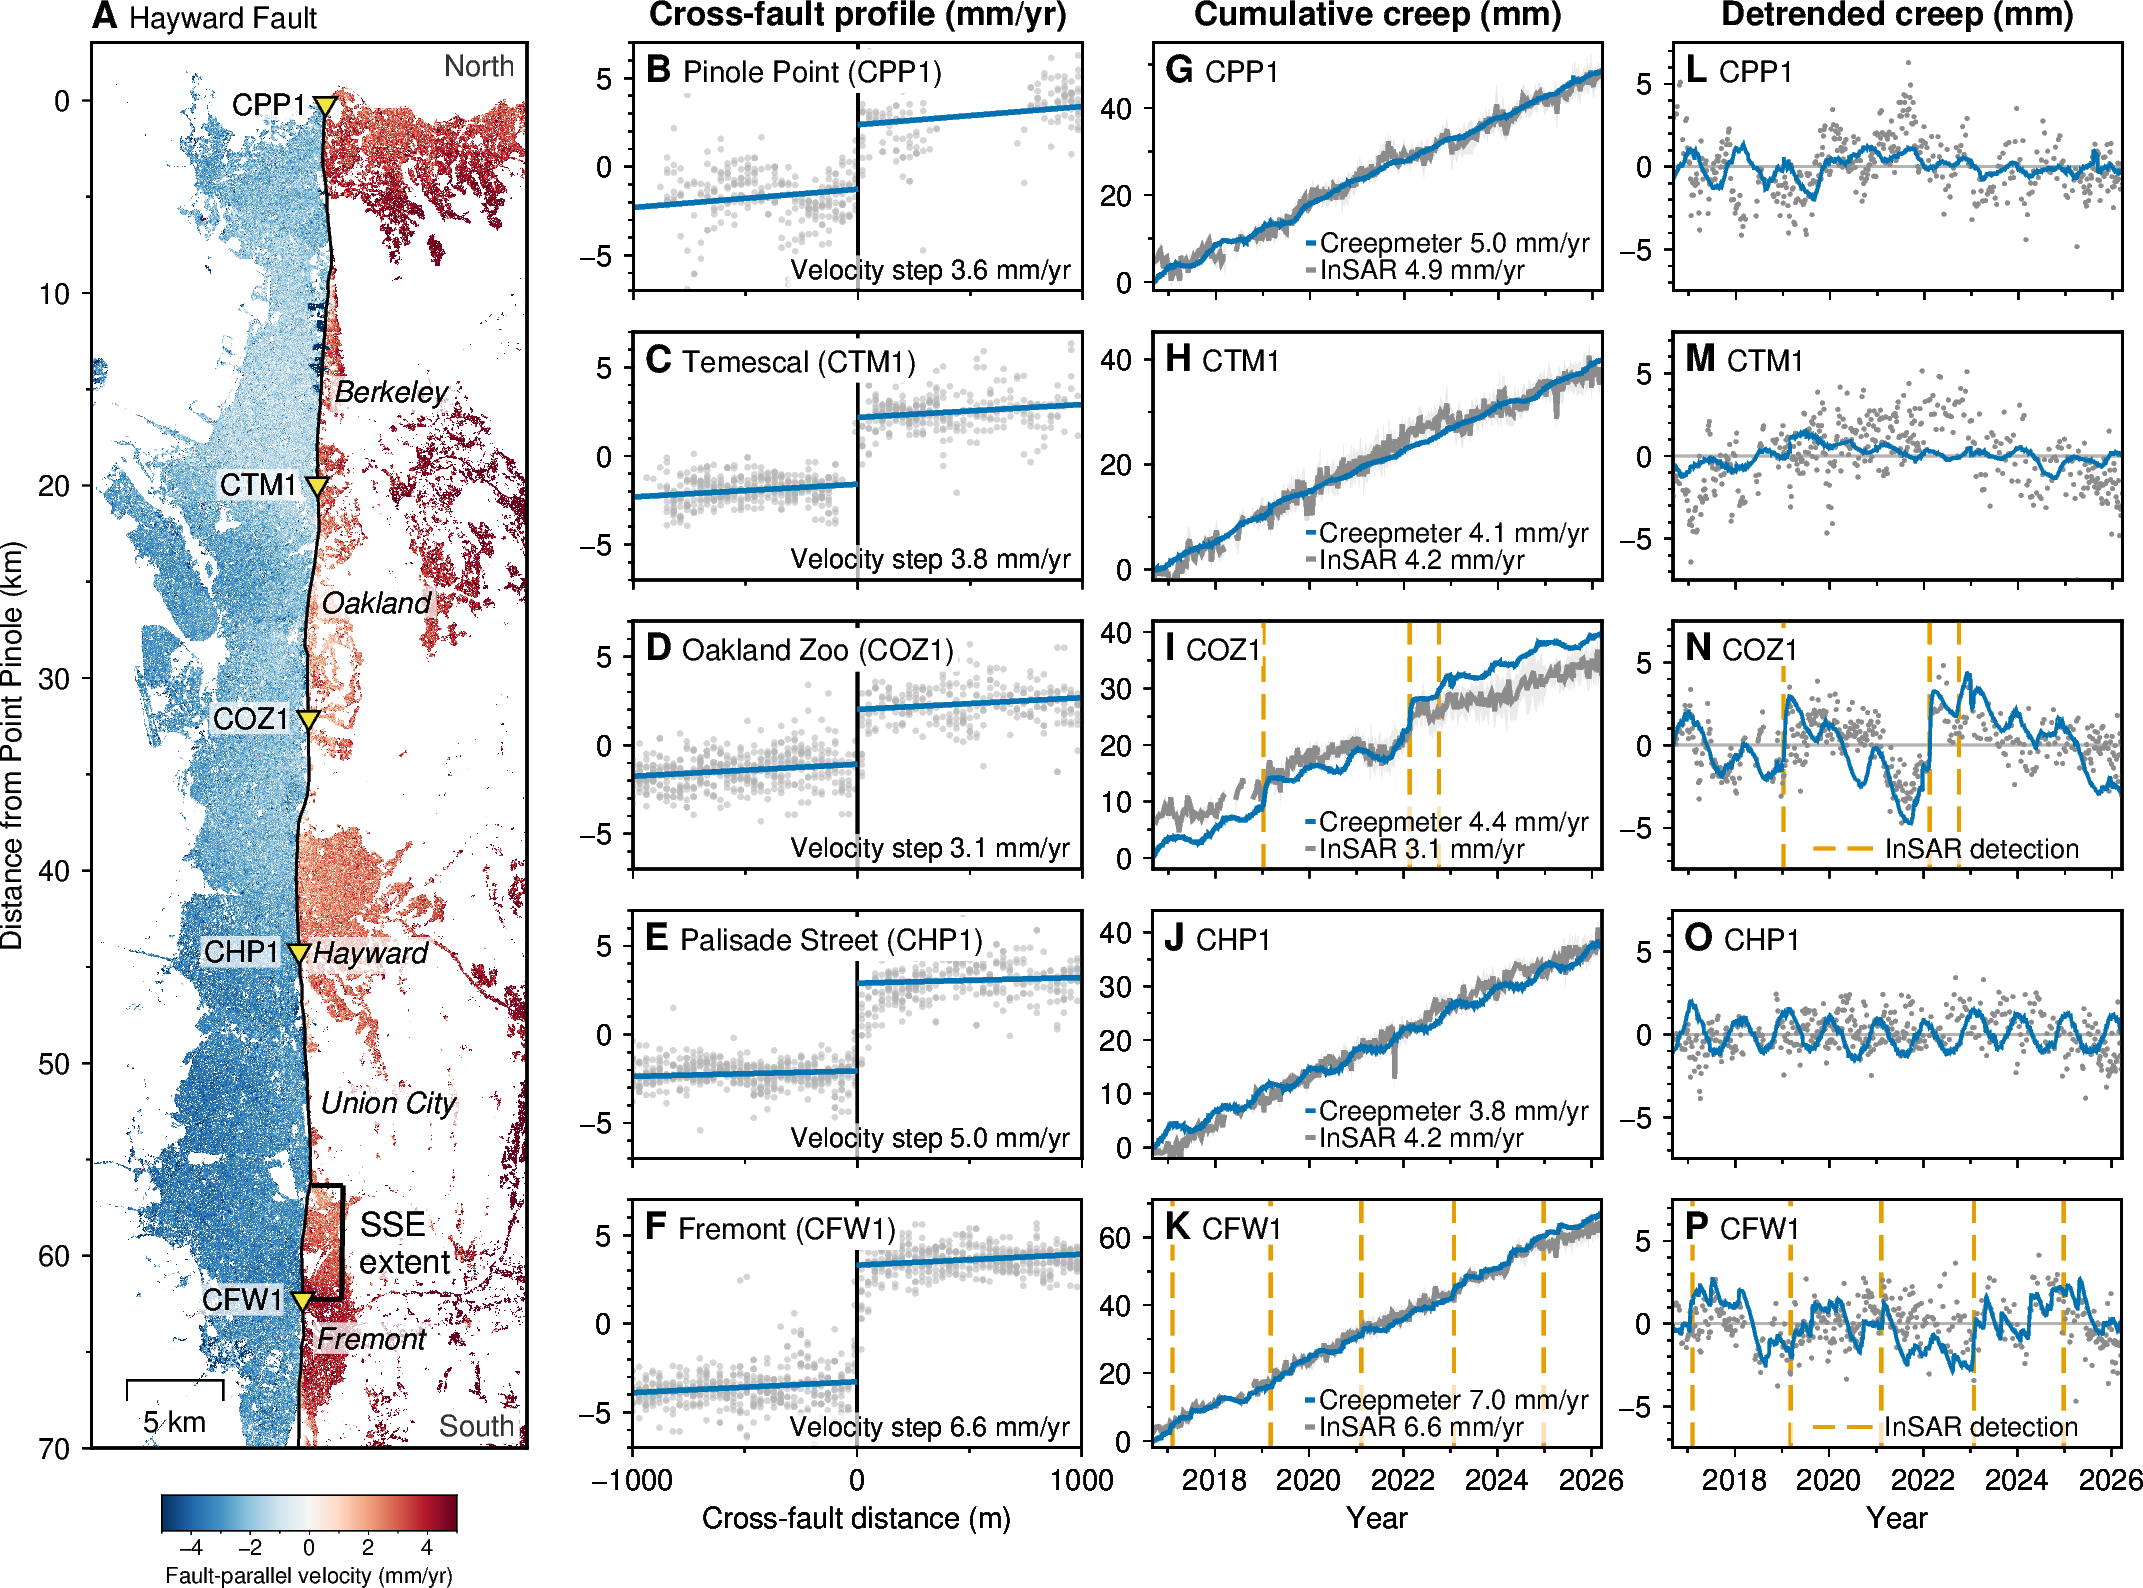

In [12]:
def runs(mask):
    """Index pairs of the contiguous True runs of a boolean mask, so that a gappy series plots with gaps.

    Parameters
    ----------
    mask : array_like of bool

    Returns
    -------
    list of tuple
        (start, stop) index pairs, stop exclusive.
    """
    edges = np.flatnonzero(np.diff(np.r_[False, np.asarray(mask, bool), False]))   # where the mask switches on or off
    return list(zip(edges[::2], edges[1::2]))


n_rows_fig = len(creepmeters)
map_h_cm = n_rows_fig * row_height_cm + (n_rows_fig - 1) * gap_row_cm    # the map spans the five rows (~12 cm)
cpt_dir = os.path.join(out_dir, "cpt")
os.makedirs(cpt_dir, exist_ok=True)
cpt_vel = utils.write_cpt(os.path.join(cpt_dir, "fp_rdbu.cpt"), "RdBu_r", -fp_clim, fp_clim)
letters_profile = "BCDEF"
letters_cumulative = "GHIJK"
letters_detrended = "LMNOP"

column_titles = ("Cross-fault profile (mm/yr)", "Cumulative creep (mm)", "Detrended creep (mm)")
row_events = {"COZ1": events_coz1, "CFW1": events_tulepond}         # the InSAR onsets drawn in a station's row
onset_pen = f"0.9p,{onset_orange},6_3:0p"                              # long dashes
fig_stem = f"figS_validation_cohmap{coh_velocity:g}_{params}_profile{max_dist_m:.0f}m_stack{stack_max}x{stack_km * 1000:.0f}m"
legend_file = os.path.join(cpt_dir, "event_lines_legend.txt")         # the key to the onset lines in N and P: a GMT legend spec, so the
with open(legend_file, "w") as legend_spec:                           # line sample is long enough to show the dashes
    legend_spec.write(f"S 0.3c - 0.5c - {onset_pen} 0.65c InSAR detection\n")
fig = pygmt.Figure()
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", MAP_FRAME_TYPE="plain",
             MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p")

# A) the map: the shared rotated fault map of Fig 1A (utils.fault_map_panel), true scale, as tall as the five rows
map_w_cm = utils.fault_map_panel(fig, frame, grid_ll, cpt_vel, map_h_cm, x_fault["ft_lon"].values, x_fault["ft_lat"].values,
                                 creepmeters, (section.km_lo, section.km_hi), letter="A", title="Hayward Fault",
                                 colorbar_frame="xa2f1+lFault-parallel velocity (mm/yr)")
assert 2.0 < map_w_cm < 5.0, f"map width {map_w_cm:.2f} cm is off (expect ~3.5 cm at true scale): region/projection changed?"
panel_w_cm = (fig_width_cm - map_axis_cm - map_w_cm - gap_map_cm - 2 * gap_col_cm) / 3.0   # the three data columns share the rest
print(f"data panels {panel_w_cm:.2f} x {row_height_cm:.2f} cm; figure {fig_width_cm} cm wide with {map_axis_cm} cm for the map's distance axis")

# B-P) five rows, north to south: profile, cumulative, detrended
fig.shift_origin(xshift=f"{map_w_cm + gap_map_cm}c", yshift=f"{map_h_cm - row_height_cm}c")
for i, (code, lat, lon, name) in enumerate(creepmeters):
    station = stations.loc[code]
    cm_dates, cm_slip = cm_data[code]
    last_row = i == len(creepmeters) - 1
    if code in row_events:
        events_in_row = row_events[code]
    else:
        events_in_row = events_all.iloc[0:0]                    # no onsets in this row
    if last_row:
        frame_sides = "WSrt"
    else:
        frame_sides = "Wsrt"

    # column 2: cross-fault velocity profile with the step
    transect = xf[(xf["code"] == code) & (xf["dist_m"].abs() <= max_dist_m)]
    profile_dist = transect["dist_m"].values.astype(float)
    profile_vel = transect["fp_vel"].values.astype(float)
    profile_vel = profile_vel - profile_vel.mean()
    profile_intercept, profile_gradient, profile_step = utils.step_fit(profile_dist, profile_vel)
    west_x = np.array([-max_dist_m, 0.0])
    east_x = np.array([0.0, max_dist_m])
    profile_region = [-max_dist_m, max_dist_m, -prof_ylim, prof_ylim]
    if last_row:
        profile_x_frame = "xa1000f500+lCross-fault distance (m)"
    else:
        profile_x_frame = "xa1000f500"
    profile_frame = [frame_sides, profile_x_frame, "ya5f1"]
    fig.basemap(region=profile_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=profile_frame)
    fig.plot(x=profile_dist, y=profile_vel, style="c0.05c", fill="gray70@45")
    fig.plot(x=[0, 0], y=[-prof_ylim, prof_ylim], pen="0.8p,black")
    fig.plot(x=west_x, y=profile_intercept + profile_gradient * west_x, pen=f"1.2p,{cm_blue}")
    fig.plot(x=east_x, y=profile_intercept + profile_gradient * east_x + profile_step, pen=f"1.2p,{cm_blue}")
    utils.text_backed(fig, position="BR", text=f"Velocity step {profile_step:.1f} mm/yr", offset=f"-{annot_offset_cm}c/{annot_offset_cm}c",
                      font="6.5p,Helvetica", clearance="0.03c")   # BR: the baseline is annot_offset_cm above the frame
    fig.text(position="TL", text=f"@%Helvetica-Bold%{letters_profile[i]}@%% @:7p:{name} ({code})@::", offset="0.1c/-0.1c",
             font="9p,Helvetica", fill="white", clearance="0.04c")
    if i == 0:
        fig.text(position="TC", text=column_titles[0], justify="BC", offset="0c/0.15c", font="8p,Helvetica-Bold", no_clip=True)
    fig.basemap(region=profile_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=profile_frame)   # frame on top: a clean edge

    # column 3: cumulative creep
    fig.shift_origin(xshift=f"{panel_w_cm + gap_col_cm}c")
    stack_dates, stack_mean, stack_std, _, _ = insar_stacks[code]
    stack_finite = np.isfinite(stack_mean)
    cm_at_stack_dates = np.interp(stack_dates[stack_finite], cm_dates, cm_slip)
    stack_display = stack_mean + float(np.mean(cm_at_stack_dates - stack_mean[stack_finite]))   # display alignment only; the rate is untouched
    cumulative_ymax = 1.05 * max(float(np.nanmax(cm_slip)), float(np.nanmax(stack_display + stack_std)))
    cumulative_region = [t0, t1, -2.0, cumulative_ymax]
    if cumulative_ymax > 45:
        cumulative_tick = 20
    else:
        cumulative_tick = 10
    if last_row:
        time_x_frame = "xa2f1+lYear"
    else:
        time_x_frame = "xa2f1"
    cumulative_frame = [frame_sides, time_x_frame, f"ya{cumulative_tick}f{cumulative_tick / 2:g}"]
    fig.basemap(region=cumulative_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=cumulative_frame)
    for _, event in events_in_row.iterrows():                       # the InSAR onsets first, under the data
        fig.plot(x=[event["onset_lo"], event["onset_lo"]], y=cumulative_region[2:], pen=onset_pen)
    for run_start, run_stop in runs(stack_finite):                  # the InSAR stack has gaps: one envelope piece per run
        if run_stop - run_start >= 2:
            run_dates = stack_dates[run_start:run_stop]
            upper = (stack_display + stack_std)[run_start:run_stop]
            lower = (stack_display - stack_std)[run_start:run_stop]
            fig.plot(x=np.r_[run_dates, run_dates[::-1]], y=np.r_[upper, lower[::-1]], fill="gray@70", close=True)
    # legend order creepmeter then InSAR, creepmeter drawn on top: its legend entry comes from an off-region (clipped) stub
    fig.plot(x=[t0 - 10, t0 - 9], y=[0, 0], pen=f"1.0p,{cm_blue}", label=f"Creepmeter {station.cm_rate:.1f} mm/yr")
    first_run = True
    for run_start, run_stop in runs(stack_finite):
        if first_run:
            insar_label = f"InSAR {station.cr_rate:.1f} mm/yr"
            first_run = False
        else:
            insar_label = None
        fig.plot(x=stack_dates[run_start:run_stop], y=stack_display[run_start:run_stop], pen=f"1.1p,{insar_grey}", label=insar_label)
    fig.plot(x=cm_dates, y=cm_slip, pen=f"1.0p,{cm_blue}")
    # Legend inside the data: 6.5p text (as the B-F annotations) on the same translucent white box (30 %,
    # utils.text_backed), a fixed narrow width just wide enough for the text, a short symbol column and tight
    # line spacing, in the bottom-right corner (below the curves), with its bottom line on the baseline of
    # the B-F 'Velocity step' annotation (legend_offset_cm, section 2); a small box padding keeps the box low.
    with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):
        fig.legend(position=f"JBR+jBR+o0.05c/{legend_offset_cm:g}c+w2.6c+l1.0", box="+gwhite@30+p0p,white@100", S="0.25c",
                   C=f"4p/{legend_clearance_cm:g}c")
    fig.text(position="TL", text=f"@%Helvetica-Bold%{letters_cumulative[i]}@%% @:7p:{code}@::", offset="0.1c/-0.1c",
             font="9p,Helvetica", fill="white", clearance="0.04c")
    if i == 0:
        fig.text(position="TC", text=column_titles[1], justify="BC", offset="0c/0.15c", font="8p,Helvetica-Bold", no_clip=True)
    fig.basemap(region=cumulative_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=cumulative_frame)

    # column 4: detrended
    fig.shift_origin(xshift=f"{panel_w_cm + gap_col_cm}c")
    detrended_region = [t0, t1, -fp_clim * 1.5, fp_clim * 1.5]
    detrended_frame = [frame_sides, time_x_frame, "ya5f1"]
    fig.basemap(region=detrended_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=detrended_frame)
    fig.plot(x=[t0, t1], y=[0, 0], pen="0.6p,gray70")
    for _, event in events_in_row.iterrows():                       # the InSAR onsets, under the data (long dashes)
        fig.plot(x=[event["onset_lo"], event["onset_lo"]], y=detrended_region[2:], pen=onset_pen)
    stack_detrended = utils.detrend(stack_dates, stack_mean)
    detrended_finite = np.isfinite(stack_detrended)
    fig.plot(x=stack_dates[detrended_finite], y=stack_detrended[detrended_finite], style="c0.04c", fill=insar_grey)
    fig.plot(x=cm_dates, y=utils.detrend(cm_dates, cm_slip), pen=f"0.8p,{cm_blue}")
    if len(events_in_row) > 0:                                      # the key to the onset lines, in the panels that have them (N, P), styled
        with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):              # as the G-K legends: 6.5p, translucent white box, bottom line on the B-F baseline
            fig.legend(spec=legend_file, position=f"JBR+jBR+o0.05c/{legend_offset_cm:g}c+w2.75c+l1.0", box="+gwhite@30+p0p,white@100",
                       C=f"4p/{legend_clearance_cm:g}c")
    fig.text(position="TL", text=f"@%Helvetica-Bold%{letters_detrended[i]}@%% @:7p:{code}@::", offset="0.1c/-0.1c",
             font="9p,Helvetica", fill="white", clearance="0.04c")
    if i == 0:
        fig.text(position="TC", text=column_titles[2], justify="BC", offset="0c/0.15c", font="8p,Helvetica-Bold", no_clip=True)
    fig.basemap(region=detrended_region, projection=f"X{panel_w_cm}c/{row_height_cm}c", frame=detrended_frame)
    if not last_row:                                                # back to column 2, one row down
        fig.shift_origin(xshift=f"-{2 * panel_w_cm + 2 * gap_col_cm}c", yshift=f"-{row_height_cm + gap_row_cm}c")

fig_val = os.path.join(fig_dir, f"{fig_stem}.png")
fig.savefig(fig_val, dpi=600, transparent=False, crop="+gwhite", anti_alias=True, show=False)
fig.savefig(fig_val.replace(".png", ".pdf"), transparent=False, crop="+gwhite", anti_alias=True, show=False)
print("Saved figure to:", fig_val)
fig.show()

## 13. The aperture ladder, from the precomputed sweep

Every cross-fault bin of the sweep is re-scored here on one fixed stack (4
rows within 0.4 km along the trace of each creepmeter, no widening), so that
the bins are comparable. The selected bin is `dist_min` to `dist_max` (30 to
150 m). Four scores are computed per bin:

1. **Rate RMS** (long-term agreement),
   $\left[\frac{1}{N}\sum_{i=1}^{N} (v_{{\rm cr},i} - v_{{\rm cm},i})^2\right]^{1/2}$ (mm/yr),
   where $v_{{\rm cr},i}$ and $v_{{\rm cm},i}$ are the least-squares
   straight-line rates of the InSAR stack and of the daily creepmeter record at
   station $i$ (section 4, no bootstrap) and $N$ is the number of stations
   whose fixed stack can be formed in that bin (the `n_stations` column).
2. **Valid data** (completeness), $100\,N_{\rm rows} / N_{\rm trace}$ (%),
   where $N_{\rm rows}$ is the number of crossings in the bin's `fp_ts.csv`
   and $N_{\rm trace}$ the number of 100 m vertices of the fault trace.
3. **COZ1 detrended correlation** (event shape), the Pearson $r$ of the
   detrended InSAR and creepmeter series at COZ1 (section 4).
4. **COZ1 step recovered** (event amplitude),
   $F = \sum_k \Delta_k^{\rm InSAR} / \sum_k \Delta_k^{\rm cm}$, where
   $\Delta_k$ is the `event_step` (section 4) of the InSAR stack and of the
   creepmeter on the InSAR epochs across the onset window (`onset_lo` to
   `onset_hi`) of large Oakland event $k$ of notebook 04 (section 6). An event
   is left out when either step cannot be measured (collars too short;
   printed) or the creepmeter step is not positive.

The standard deviation of the COZ1 stack residual after constant, rate and
annual sine and cosine (mm) is also written to the table. The smaller October
2022 COZ1 event is not scored: it is a creep surge rather than a step, and
its collars contain the February 2022 event. The step fraction scores the bins
on the coherence 0.9 sweep; the transient amplitude of the paper is notebook
04's joint model at COZ1 (section 10).

In [13]:
def rate_annual_residual_sd(dates, values):
    """Standard deviation of the residual after constant, rate and annual sine and cosine.

    Parameters
    ----------
    dates : numpy.ndarray
        Epochs (decimal years).
    values : numpy.ndarray
        Cumulative creep (mm).

    Returns
    -------
    float
        The residual standard deviation (mm).
    """
    design_matrix = utils.joint_design(dates, [])                     # constant, rate, annual sine and cosine
    coef = np.linalg.lstsq(design_matrix, values, rcond=None)[0]
    return float(np.std(values - design_matrix @ coef))


coz1_lat = None
for code, lat, lon, name in creepmeters:
    if code == "COZ1":
        coz1_lat = lat
assert coz1_lat is not None, "COZ1 is not in the creepmeter list"

ladder_rows = []
for set_name, inner, outer in ladder_bins:
    sweep_tag = f"ap{inner}-{outer}m_coh{ladder_coh:g}_mp{min_points}"
    sweep_fp = cp.read_creep_ts(os.path.join(common_paths["sweep_dir"], sweep_tag, "fp_ts.csv"))
    # rate RMS over the stations where the fixed stack can be formed
    rate_differences = []
    for code, lat, lon, name in creepmeters:
        stacked = stack_insar(sweep_fp, lat, half_km=ladder_stack_km, n_stack=ladder_n_stack, exact=True)
        if stacked is None:
            continue
        stack_dates = stacked[0]
        stack_mean = stacked[1]
        finite = np.isfinite(stack_mean)
        cm_dates, cm_slip = cm_data[code]
        insar_rate = np.polyfit(stack_dates[finite], stack_mean[finite], 1)[0]
        cm_rate = np.polyfit(cm_dates, cm_slip, 1)[0]
        rate_differences.append(insar_rate - cm_rate)
    # COZ1: detrended correlation, step fraction, and the residual scatter
    det_r = np.nan
    step_frac = np.nan
    resid_sd = np.nan
    stacked = stack_insar(sweep_fp, coz1_lat, half_km=ladder_stack_km, n_stack=ladder_n_stack, exact=True)
    if stacked is not None:
        stack_dates = stacked[0]
        stack_mean = stacked[1]
        finite = np.isfinite(stack_mean)
        insar_dates = stack_dates[finite]
        insar_slip = stack_mean[finite]
        cm_dates, cm_slip = cm_data["COZ1"]
        cm_on_insar_dates = np.interp(insar_dates, cm_dates, cm_slip)
        insar_detrended = utils.detrend(insar_dates, insar_slip)
        cm_detrended = utils.detrend(insar_dates, cm_on_insar_dates)
        both_finite = np.isfinite(insar_detrended) & np.isfinite(cm_detrended)
        det_r = float(np.corrcoef(insar_detrended[both_finite], cm_detrended[both_finite])[0, 1])
        insar_steps = []
        cm_steps = []
        for event in events_coz1_large.itertuples():                # the onset windows of the two large Oakland events (section 6)
            insar_steps.append(event_step(insar_dates, insar_slip, event.onset_lo, event.onset_hi))
            cm_steps.append(event_step(insar_dates, cm_on_insar_dates, event.onset_lo, event.onset_hi))
        insar_steps = np.array(insar_steps)
        cm_steps = np.array(cm_steps)
        scored = np.isfinite(insar_steps) & np.isfinite(cm_steps) & (cm_steps > 0)
        if not scored.all():
            print(f"  {sweep_tag}: {int((~scored).sum())} of the {len(events_coz1_large)} large COZ1 events not scorable (short collars)")
        if scored.any():
            step_frac = float(np.sum(insar_steps[scored]) / np.sum(cm_steps[scored]))
        resid_sd = rate_annual_residual_sd(insar_dates, insar_slip)
    if len(rate_differences) > 0:
        rate_rms = float(np.sqrt(np.mean(np.square(rate_differences))))
    else:
        rate_rms = np.nan
    ladder_rows.append(dict(set=set_name, tag=sweep_tag, inner=inner, outer=outer, centre=(inner + outer) / 2, width=outer - inner,
                            n_stations=len(rate_differences), valid=100.0 * sweep_fp.shape[0] / len(x_fault),
                            rate_rms=rate_rms, coz1_det_r=det_r, coz1_step_frac=step_frac, coz1_resid_sd_mm=resid_sd))
ladder = pd.DataFrame(ladder_rows)
ladder.to_csv(os.path.join(out_dir, "sweep_ladder_scores.csv"), index=False)
print(ladder.drop(columns=["tag"]).round(3).to_string(index=False))
selected_bin = ladder[(ladder.inner == selected[0]) & (ladder.outer == selected[1])].iloc[0]
print("")
print(f"selected bin {selected[0]}-{selected[1]} m at coherence {ladder_coh}: rate RMS {selected_bin.rate_rms:.2f} mm/yr on "
      f"{selected_bin.n_stations} stations, {selected_bin.valid:.0f}% of the trace, COZ1 det r {selected_bin.coz1_det_r:.2f}, "
      f"step recovered {100 * selected_bin.coz1_step_frac:.0f}%")

# the chosen bin at the three coherence thresholds (the sweep's own summary table);
# the paper's stream uses coherence 0.7
coh_rows = []
for _, summary_row in selected_by_coh.iterrows():
    sweep_fp = cp.read_creep_ts(os.path.join(common_paths["sweep_dir"], summary_row.tag, "fp_ts.csv"))
    coh_rows.append(dict(coh=summary_row.coh, rate_rms=summary_row.rate_rms, rate_bias=summary_row.rate_bias, n_crossings=sweep_fp.shape[0]))
coh_table = pd.DataFrame(coh_rows)
print(coh_table.round(3).to_string(index=False))

     set  inner  outer  centre  width  n_stations  valid  rate_rms  coz1_det_r  coz1_step_frac  coz1_resid_sd_mm
   fixed      0    100    50.0    100           4 54.488     1.100       0.593           0.430             1.482
   fixed     50    150   100.0    100           5 59.039     0.601       0.511           0.500             1.689
   fixed    100    200   150.0    100           4 62.073     0.752       0.478           0.705             1.823
   fixed    150    250   200.0    100           4 58.534     0.654       0.490           0.725             2.011
   fixed    200    300   250.0    100           4 57.775     0.805       0.347           0.878             2.222
   fixed    300    400   350.0    100           4 55.373     0.873       0.221           0.347             2.332
   fixed    400    500   450.0    100           4 55.626     1.036       0.312           0.432             2.605
 growing    100    300   200.0    200           4 70.417     0.752       0.428           0.702  

## 14. Figure: the aperture ladder (supplement)

Four panels, one per score of section 13, against distance from the trace.
Each tested bin is a horizontal bar from its inner to its outer edge with a
dot at its centre (grey); the selected 30 to 150 m bin (the crossings of the
time series) is in vermillion. The shaded strip is the 60 m near-trace cut of
the slip models (the DISP-S1 phase-linking half-width).

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-04/figS_binning_ladder_coh0.9_mp5_stack4x0.4km.png


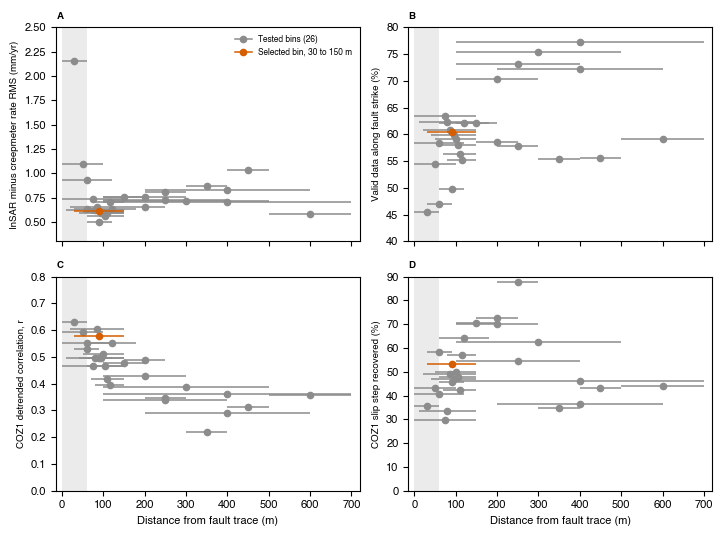

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharex=True)
axes = axes.ravel()
is_selected = []
for bin_row in ladder.itertuples():
    is_selected.append((bin_row.inner, bin_row.outer) == selected)
ordered = ladder.assign(is_selected=is_selected).sort_values("is_selected")      # the selected bin drawn last, on top
selected_colour = "#D55E00"                                                      # Okabe-Ito vermillion


def draw_ladder_scores(ax, score_column, scale=1.0):
    """Draw one bar per bin (inner to outer edge) at the bin's score, with a dot at the bin centre.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
    score_column : str
        Column of the ladder table to plot.
    scale : float
        Factor applied to the score (100 for a percentage).
    """
    for _, bin_row in ordered.iterrows():
        if not np.isfinite(bin_row[score_column]):
            continue
        score = scale * bin_row[score_column]
        if bin_row.is_selected:
            colour = selected_colour
            layer = 6
        else:
            colour = "0.55"
            layer = 2
        ax.plot([bin_row.inner, bin_row.outer], [score, score], "-", color=colour, lw=1.1, zorder=layer, solid_capstyle="butt")
        ax.plot(bin_row.centre, score, "o", ms=4.5, color=colour, zorder=layer + 1)


for ax in axes:
    ax.axvspan(0, excluded_m, facecolor="0.92", zorder=0)
    ax.set_xlim(-15, 720)
ladder_panels = ((axes[0], "rate_rms", "InSAR minus creepmeter rate RMS (mm/yr)", (0.3, 2.5), "A", 1),
                 (axes[1], "valid", "Valid data along fault strike (%)", (40, 80), "B", 1),
                 (axes[2], "coz1_det_r", "COZ1 detrended correlation, r", (0, 0.8), "C", 1),
                 (axes[3], "coz1_step_frac", "COZ1 slip step recovered (%)", (0, 90), "D", 100))
for ax, score_column, y_label, y_limits, letter, scale in ladder_panels:
    scores = scale * ladder[score_column].dropna()
    assert scores.between(*y_limits).all(), f"{score_column}: scores {scores.min():.2f} to {scores.max():.2f} fall outside the panel {y_limits}"
    draw_ladder_scores(ax, score_column, scale)
    ax.set_ylabel(y_label, fontsize=7)
    ax.set_ylim(*y_limits)
    utils.panel_title(ax, letter)
for ax in axes[2:]:
    ax.set_xlabel("Distance from fault trace (m)")
axes[0].legend(handles=[Line2D([], [], color="0.55", lw=1.1, marker="o", ms=4.5, label=f"Tested bins ({len(ladder)})"),
                        Line2D([], [], color=selected_colour, lw=1.1, marker="o", ms=4.5, label=f"Selected bin, {selected[0]} to {selected[1]} m")],
               fontsize=6, loc="upper right")
fig.tight_layout()
fig_lad = os.path.join(fig_dir, f"figS_binning_ladder_coh{ladder_coh:g}_mp{min_points}_stack{ladder_n_stack}x{ladder_stack_km}km.png")
fig.savefig(fig_lad, dpi=300)
fig.savefig(fig_lad.replace(".png", ".pdf"))
print("Saved figure to:", fig_lad)
plt.show()

## 15. Register

The stats file `05_validation_stats.txt` (every table above) and the registry
rows `05_*` quoted in the paper.

In [15]:
stats_lines += ["", f"APERTURE LADDER (precomputed sweep at coherence {ladder_coh}, fixed {ladder_n_stack}-row stack within {ladder_stack_km} km along the trace)",
                ladder.drop(columns=["tag"]).round(3).to_string(index=False), "",
                f"chosen bin {selected[0]}-{selected[1]} m by coherence threshold:", coh_table.round(3).to_string(index=False)]
sidecar = REG.sidecar("05_validation", stats_lines)
for code, station in stations.iterrows():
    for column_key, label in (("cm", "creepmeter"), ("cr", "crossing"), ("st", "step")):
        REG.register(f"05_{code}_{label}_rate_mm_yr", station[f"{column_key}_rate"], "mm/yr", 2, where="M4, Fig S validation", cell="bootstrap", sidecar=sidecar)
        REG.register(f"05_{code}_{label}_ci_lo", station[f"{column_key}_lo"], "mm/yr", 2, where="M4", cell="bootstrap", sidecar=sidecar)
        REG.register(f"05_{code}_{label}_ci_hi", station[f"{column_key}_hi"], "mm/yr", 2, where="M4", cell="bootstrap", sidecar=sidecar)
    REG.register(f"05_{code}_det_r", station.det_r, "1", 2, where="M4", cell="bootstrap", sidecar=sidecar)
    REG.register(f"05_{code}_det_rmse_mm", station.det_rmse, "mm", 2, where="M4", cell="bootstrap", sidecar=sidecar)
REG.register("05_rate_rms_mm_yr", agreement_stats["cross"]["rms"], "mm/yr", 2, where="P2, M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_bias_mm_yr", agreement_stats["cross"]["bias"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_maxabs_mm_yr", agreement_stats["cross"]["maxabs"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_rms_excl_coz1_mm_yr", agreement_stats["cross_excl_coz1"]["rms"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_step_rms_mm_yr", agreement_stats["step"]["rms"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_step_bias_mm_yr", agreement_stats["step"]["bias"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_noise_floor_det_rmse_mm", floor_rmse, "mm", 2, where="P2, M4", cell="noise-floor", sidecar=sidecar)
for _, window in cfw_windows.iterrows():
    onset_tag = window.onset_day.replace("-", "_")                       # key label: the onset day (UTC)
    REG.register(f"05_cfw1_win_{onset_tag}_mm", window.slip_win_mm, "mm", 2, where="P3, Fig S validation", cell="cfw1-windows", sidecar=sidecar)
    REG.register(f"05_cfw1_win_{onset_tag}_expected_mm", window.expect_win_mm, "mm", 2, where="P3", cell="cfw1-windows", sidecar=sidecar)
    REG.register(f"05_cfw1_win_{onset_tag}_data_pct", window.cover_pct, "%", 0, where="P3", cell="cfw1-windows", sidecar=sidecar)
for creepmeter_code, (n_covered, n_matched) in gittins_counts.items():
    REG.register(f"05_gittins_{creepmeter_code.lower()}_windows_covered", n_covered, "count", 0, where="P3, M5", cell="gittins", sidecar=sidecar)
    REG.register(f"05_gittins_{creepmeter_code.lower()}_windows_matched", n_matched, "count", 0, where="P3, M5", cell="gittins", sidecar=sidecar)
REG.register("05_gittins_cfw1_n_events", len(background), "count", 0, where="P3, table Gittins", cell="gittins-cfw1", sidecar=sidecar)
REG.register("05_gittins_cfw1_rate_per_yr", cfw1_rate_per_yr, "1/yr", 1, where="P3, table Gittins", cell="gittins-cfw1", sidecar=sidecar)
REG.register("05_gittins_cfw1_median_slip_mm", cfw1_median_slip_mm, "mm", 2, where="P3, table Gittins", cell="gittins-cfw1", sidecar=sidecar)
REG.register("05_gittins_cfw1_catalogue_end", str(cfw1_end.date()), "date", 0, where="P3, table Gittins", cell="gittins-cfw1", sidecar=sidecar)
for year, (step_mm, n_crossings) in cfw1_insar_steps.items():
    REG.register(f"05_cfw1_insar_step_{year}_mm", step_mm, "mm", 1, where="P3, table Gittins", cell="cfw1-insar", sidecar=sidecar)
    REG.register(f"05_cfw1_insar_step_{year}_n", n_crossings, "count", 0, where="table Gittins", cell="cfw1-insar", sidecar=sidecar)
REG.register("05_cfw1_insar_step_sigma_mm", cfw1_insar_sigma, "mm", 1, where="P3, table Gittins", cell="cfw1-insar", sidecar=sidecar)
for event_id, step_mm in gittins_step.items():
    REG.register(f"05_cfw1_insar_step_gittins_{event_id.lower()}_mm", step_mm, "mm", 1, where="table Gittins", cell="cfw1-gittins-steps", sidecar=sidecar)
REG.register("05_cfw1_insar_step_gittins_sigma_mm", gittins_step_sigma, "mm", 1, where="table Gittins", cell="cfw1-gittins-steps", sidecar=sidecar)
REG.register("05_gittins_cfw1_window_pad_d", gittins_window_pad_days, "d", 0, where="table Gittins", cell="gittins-cfw1", sidecar=sidecar)
for label, pct in recovery_pct.items():
    REG.register(f"05_coz1_amp_recovery_{label}_pct", pct, "pct", 0, where="M4", cell="coz1-amplitude", sidecar=sidecar)
REG.register("05_coz1_amp_recovery_mean_pct", recovery_mean_pct, "pct", 0, where="M4", cell="coz1-amplitude", sidecar=sidecar)
REG.register(f"05_coz1_insar_minus_cm_before_{first_coz1_label}_mm", coz1_drift_before_mm, "mm", 1, where="M4", cell="coz1-amplitude", sidecar=sidecar)
REG.register(f"05_coz1_insar_minus_cm_after_{first_coz1_label}_mm", coz1_drift_after_mm, "mm", 1, where="M4", cell="coz1-amplitude", sidecar=sidecar)
REG.register("05_det_rmse_min_mm", stations.det_rmse.min(), "mm", 2, where="M4", cell="noise-floor", sidecar=sidecar)
REG.register("05_det_rmse_max_mm", stations.det_rmse.max(), "mm", 2, where="M4", cell="noise-floor", sidecar=sidecar)
REG.register("05_noise_floor_steady_std_mm", floor_steady_std, "mm", 2, where="M4 (alternative definition)", cell="noise-floor", sidecar=sidecar)
for _, coh_row in coh_table.iterrows():
    REG.register(f"05_coh{coh_row.coh:g}_rate_rms_mm_yr", coh_row.rate_rms, "mm/yr", 2, where="M3", cell="ladder", sidecar=sidecar)
    REG.register(f"05_coh{coh_row.coh:g}_n_crossings", int(coh_row.n_crossings), "count", 0, where="M3", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_n_bins", len(ladder), "count", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_rate_rms", selected_bin.rate_rms, "mm/yr", 2, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_valid_pct", selected_bin.valid, "pct", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_coz1_det_r", selected_bin.coz1_det_r, "1", 2, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_coz1_step_pct", 100 * selected_bin.coz1_step_frac, "pct", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/05_validation/05_validation_stats.txt
  registered 05_CPP1_creepmeter_rate_mm_yr = 5.05 mm/yr  -> M4, Fig S validation
  registered 05_CPP1_creepmeter_ci_lo = 4.95 mm/yr  -> M4
  registered 05_CPP1_creepmeter_ci_hi = 5.14 mm/yr  -> M4
  registered 05_CPP1_crossing_rate_mm_yr = 4.91 mm/yr  -> M4, Fig S validation
  registered 05_CPP1_crossing_ci_lo = 4.66 mm/yr  -> M4
  registered 05_CPP1_crossing_ci_hi = 5.19 mm/yr  -> M4


  registered 05_CPP1_step_rate_mm_yr = 3.65 mm/yr  -> M4, Fig S validation
  registered 05_CPP1_step_ci_lo = 2.46 mm/yr  -> M4
  registered 05_CPP1_step_ci_hi = 4.78 mm/yr  -> M4
  registered 05_CPP1_det_r = 0.32 1  -> M4
  registered 05_CPP1_det_rmse_mm = 1.66 mm  -> M4
  registered 05_CTM1_creepmeter_rate_mm_yr = 4.11 mm/yr  -> M4, Fig S validation
  registered 05_CTM1_creepmeter_ci_lo = 4.02 mm/yr  -> M4


  registered 05_CTM1_creepmeter_ci_hi = 4.21 mm/yr  -> M4
  registered 05_CTM1_crossing_rate_mm_yr = 4.19 mm/yr  -> M4, Fig S validation
  registered 05_CTM1_crossing_ci_lo = 3.91 mm/yr  -> M4
  registered 05_CTM1_crossing_ci_hi = 4.48 mm/yr  -> M4
  registered 05_CTM1_step_rate_mm_yr = 3.77 mm/yr  -> M4, Fig S validation
  registered 05_CTM1_step_ci_lo = 3.32 mm/yr  -> M4
  registered 05_CTM1_step_ci_hi = 4.22 mm/yr  -> M4


  registered 05_CTM1_det_r = 0.37 1  -> M4
  registered 05_CTM1_det_rmse_mm = 1.88 mm  -> M4
  registered 05_COZ1_creepmeter_rate_mm_yr = 4.43 mm/yr  -> M4, Fig S validation
  registered 05_COZ1_creepmeter_ci_lo = 4.10 mm/yr  -> M4
  registered 05_COZ1_creepmeter_ci_hi = 4.75 mm/yr  -> M4
  registered 05_COZ1_crossing_rate_mm_yr = 3.06 mm/yr  -> M4, Fig S validation
  registered 05_COZ1_crossing_ci_lo = 2.83 mm/yr  -> M4


  registered 05_COZ1_crossing_ci_hi = 3.28 mm/yr  -> M4
  registered 05_COZ1_step_rate_mm_yr = 3.09 mm/yr  -> M4, Fig S validation
  registered 05_COZ1_step_ci_lo = 2.60 mm/yr  -> M4
  registered 05_COZ1_step_ci_hi = 3.61 mm/yr  -> M4
  registered 05_COZ1_det_r = 0.58 1  -> M4
  registered 05_COZ1_det_rmse_mm = 1.67 mm  -> M4
  registered 05_CHP1_creepmeter_rate_mm_yr = 3.81 mm/yr  -> M4, Fig S validation


  registered 05_CHP1_creepmeter_ci_lo = 3.75 mm/yr  -> M4
  registered 05_CHP1_creepmeter_ci_hi = 3.86 mm/yr  -> M4
  registered 05_CHP1_crossing_rate_mm_yr = 4.20 mm/yr  -> M4, Fig S validation
  registered 05_CHP1_crossing_ci_lo = 4.08 mm/yr  -> M4
  registered 05_CHP1_crossing_ci_hi = 4.32 mm/yr  -> M4
  registered 05_CHP1_step_rate_mm_yr = 4.95 mm/yr  -> M4, Fig S validation
  registered 05_CHP1_step_ci_lo = 4.31 mm/yr  -> M4


... (10 outputs left out)

  registered 05_det_rmse_max_mm = 1.88 mm  -> M4
  registered 05_noise_floor_steady_std_mm = 1.75 mm  -> M4 (alternative definition)
  registered 05_coh0.7_rate_rms_mm_yr = 0.67 mm/yr  -> M3
  registered 05_coh0.7_n_crossings = 611 count  -> M3
  registered 05_coh0.8_rate_rms_mm_yr = 0.63 mm/yr  -> M3
  registered 05_coh0.8_n_crossings = 565 count  -> M3
  registered 05_coh0.9_rate_rms_mm_yr = 0.58 mm/yr  -> M3


  registered 05_coh0.9_n_crossings = 478 count  -> M3
  registered 05_ladder_n_bins = 26 count  -> M3, Fig S ladder
  registered 05_ladder_selected_rate_rms = 0.61 mm/yr  -> M3, Fig S ladder
  registered 05_ladder_selected_valid_pct = 60 pct  -> M3, Fig S ladder
  registered 05_ladder_selected_coz1_det_r = 0.58 1  -> M3, Fig S ladder
  registered 05_ladder_selected_coz1_step_pct = 53 pct  -> M3, Fig S ladder


Wrote the numbers to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md


'/Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md'